In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from data import GDPHMM_OAR_V3
from results import ModelResults, ModelComparison, build_dataset, is_higher_better


In [3]:
dataset = build_dataset('test')

# Dose Prediction

In [8]:
# 10x pred models (100-series) - Diffusion
mamba_099_pred = ModelResults('100-mamba', 'ddpm-1000', 99, 'test', dataset)
mamba_199_pred = ModelResults('100-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_099_pred = ModelResults('101-beamdiff', 'ddpm-1000', 99, 'test', dataset)
beamdiff_199_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_099_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 99, 'test', dataset)
spdiffdose_199_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_099_pred = ModelResults('103-dosediff', 'ddpm-1000', 99, 'test', dataset)
dosediff_199_pred = ModelResults('103-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_099_pred = ModelResults('104-diffdp', 'ddpm-1000', 99, 'test', dataset)
diffdp_199_pred = ModelResults('104-diffdp', 'ddpm-1000', 199, 'test', dataset)
ddpm_mednext_m_099_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 99, 'test', dataset)
ddpm_mednext_m_199_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 199, 'test', dataset)

# 10x pred models (100-series) - UNet
c3d_2d_099_pred = ModelResults('105-c3d-2d', 'unet', 99, 'test', dataset)
c3d_2d_199_pred = ModelResults('105-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_099_pred = ModelResults('106-mednext-m', 'unet', 99, 'test', dataset)
mednext_m_199_pred = ModelResults('106-mednext-m', 'unet', 199, 'test', dataset)
deeplabv3plus_099_pred = ModelResults('107-deeplabv3plus', 'unet', 99, 'test', dataset)
deeplabv3plus_199_pred = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
hdunet_099_pred = ModelResults('109-hdunet', 'unet', 99, 'test', dataset)
hdunet_199_pred = ModelResults('109-hdunet', 'unet', 199, 'test', dataset)
mednext_v2_m_099_pred = ModelResults('110-mednext-v2-m', 'unet', 99, 'test', dataset)
mednext_v2_m_199_pred = ModelResults('110-mednext-v2-m', 'unet', 199, 'test', dataset)

In [9]:
pred_comparison = ModelComparison([
    mamba_199_pred,
    beamdiff_199_pred,
    spdiffdose_199_pred,
    dosediff_199_pred,
    diffdp_199_pred,
    ddpm_mednext_m_199_pred,
    c3d_2d_199_pred,
    mednext_m_199_pred,
	  mednext_v2_m_199_pred,
    deeplabv3plus_199_pred,
    hdunet_199_pred,
], [
  'MD-Dose',
  'BeamDiff',
  'SPDiffDose',
  'DoseDiff',
  'DiffDP',
  'DDPM-MedNeXt-M',
  'C3D-2D',
  'MedNeXt-M',
  'MedNeXt-M v2',
  'DeepLabV3+',
  'HDUNet',
], [
	'Diffusion',
	'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
])

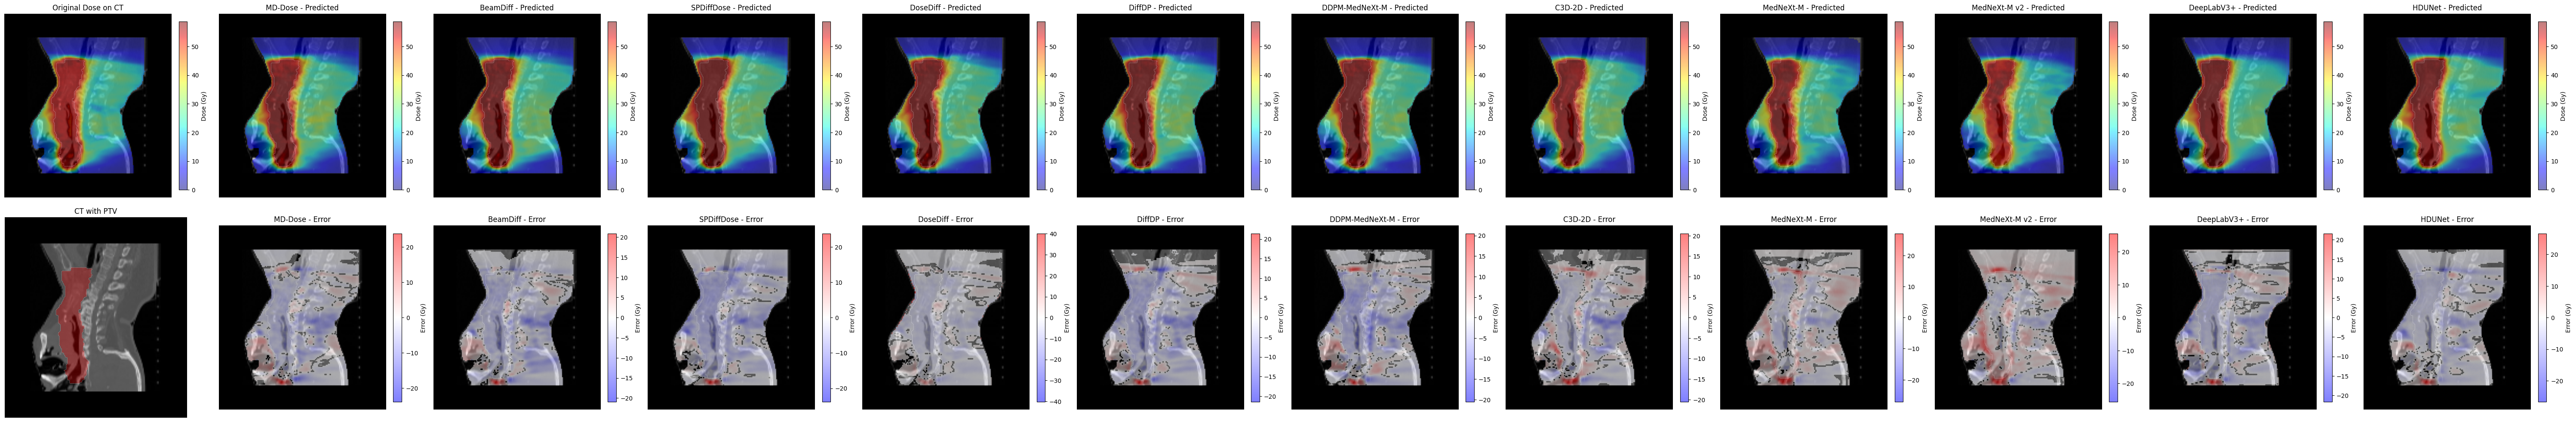

In [10]:
# sample = '0522c0027+A4Ac+MOS_30413'
# sample = 'HNSCC-01-0057+A4Ac+MOS_50995'
# sample = 'HNSCC-01-0060+A4Ac+MOS_19273'
# sample = '0522c0142+A4Ac+MOS_43691'
sample = 'HNSCC-01-0164+A4Ac+MOS_52248' # 100
# sample = 'HN-CHUM-003+S2A4Ac+MOS_20285' ##
# sample = 'HNSCC-01-0026+A4Ac+MOS_5856'
# sample = '0522c0723+A4Ac+MOS_2890'
# sample = '0522c0629+A4Ac+MOS_1367'
# sample = 'HNC_004+A4Ac+MOS_11506' #

ax = pred_comparison.visualise_slice_comparison_with_ct(sample, 100, axis='sagittal')

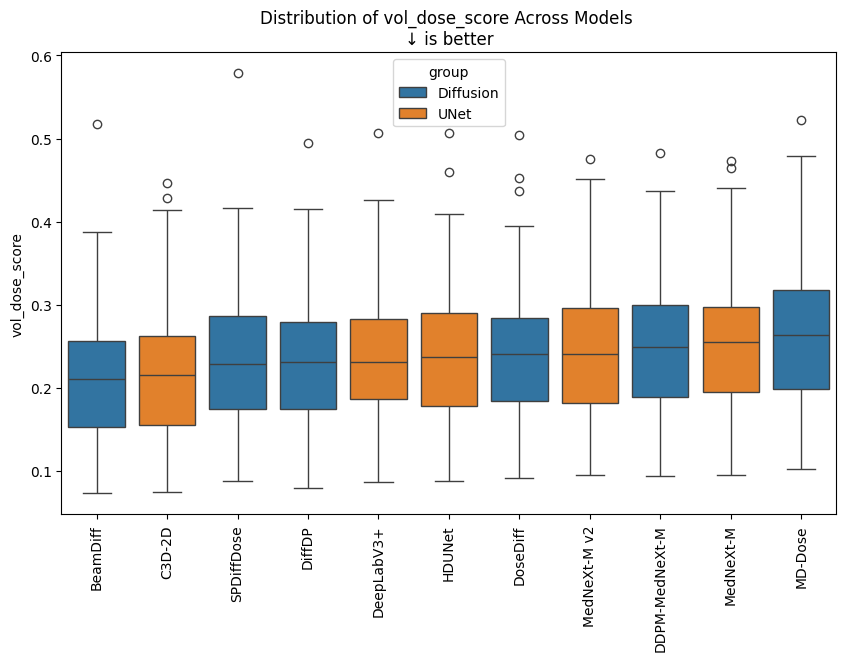

In [12]:
_ = pred_comparison.plot_metric_distribution('vol_dose_score', sort=True)

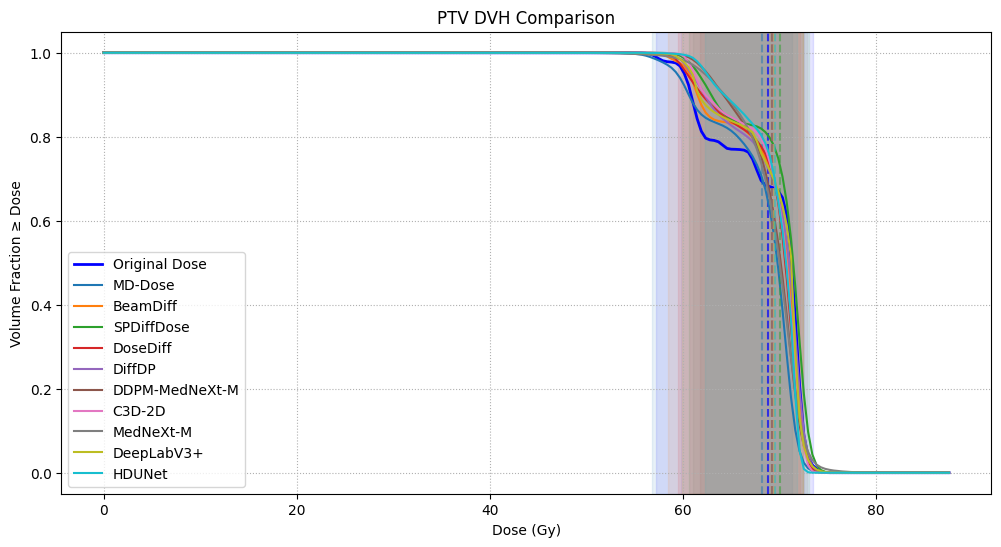

In [11]:
_ = pred_comparison.plot_ptv_dvh()

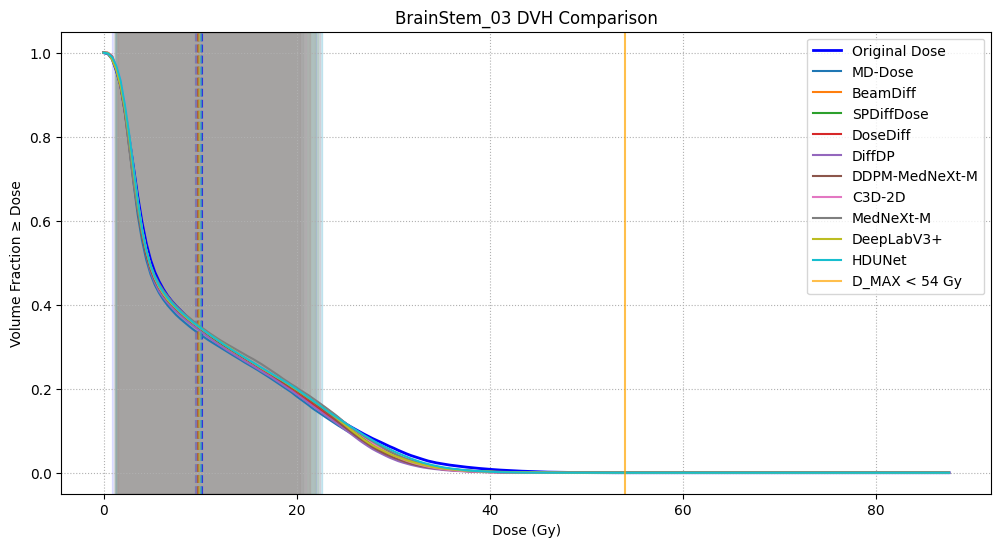

In [12]:
_ = pred_comparison.plot_brainstem_dvh()

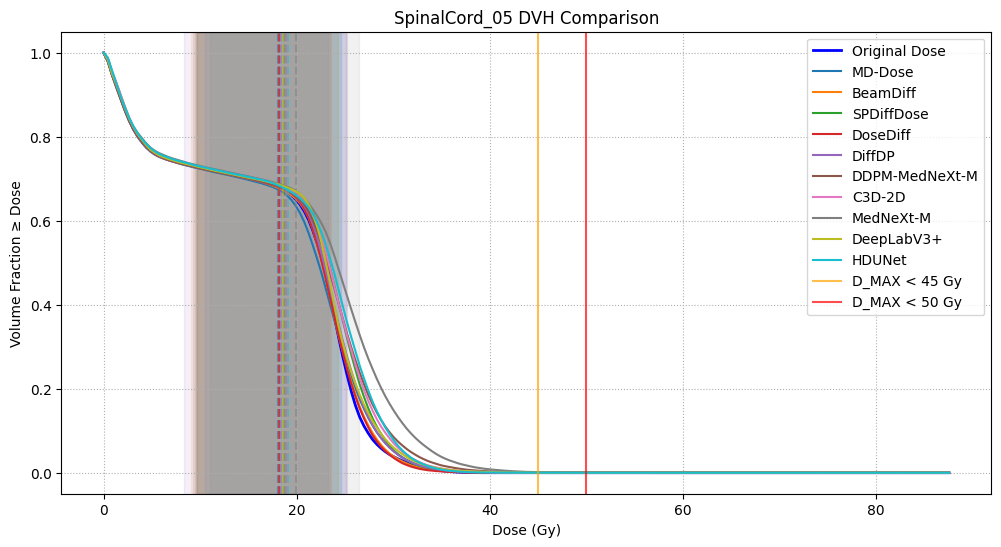

In [13]:
_ = pred_comparison.plot_spinal_cord_dvh()

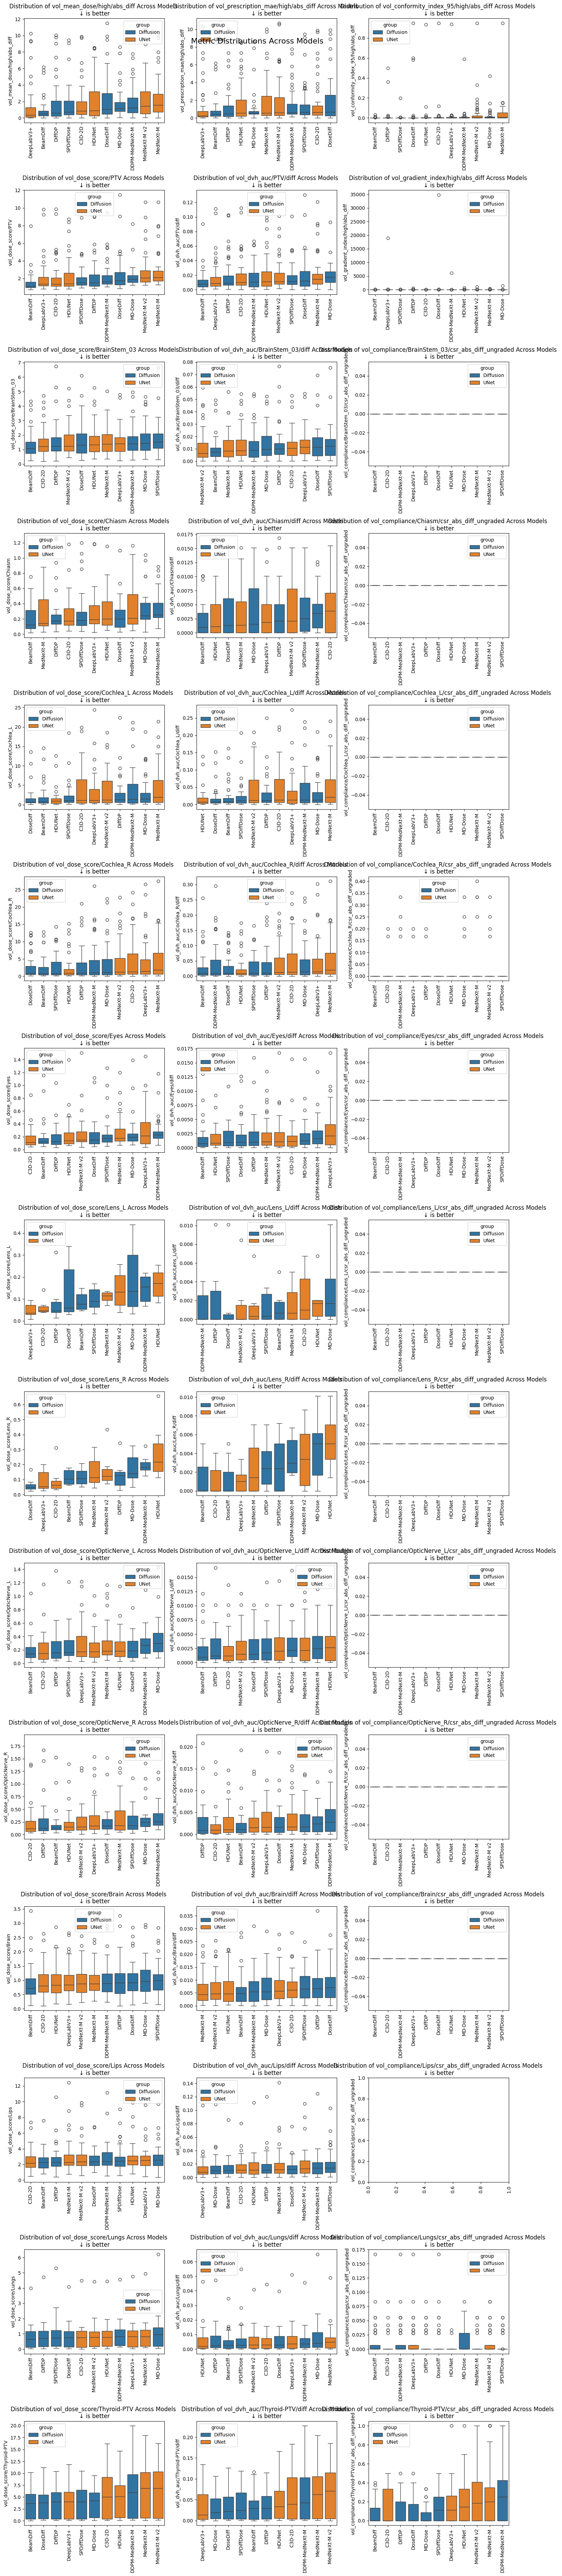

In [ ]:
_ = pred_comparison.plot_metric_distributions([
  'vol_mean_dose/high/abs_diff', 'vol_prescription_mae/high/abs_diff', 'vol_conformity_index_95/high/abs_diff',
  'vol_dose_score/PTV', 'vol_dvh_auc/PTV/diff', 'vol_gradient_index/high/abs_diff',
  'vol_dose_score/BrainStem_03', 'vol_dvh_auc/BrainStem_03/diff', 'vol_compliance/BrainStem_03/csr_abs_diff_ungraded',
  'vol_dose_score/Chiasm', 'vol_dvh_auc/Chiasm/diff', 'vol_compliance/Chiasm/csr_abs_diff_ungraded',
  'vol_dose_score/Cochlea_L', 'vol_dvh_auc/Cochlea_L/diff', 'vol_compliance/Cochlea_L/csr_abs_diff_ungraded',
  'vol_dose_score/Cochlea_R', 'vol_dvh_auc/Cochlea_R/diff', 'vol_compliance/Cochlea_R/csr_abs_diff_ungraded',
  'vol_dose_score/Eyes', 'vol_dvh_auc/Eyes/diff', 'vol_compliance/Eyes/csr_abs_diff_ungraded',
  'vol_dose_score/Lens_L', 'vol_dvh_auc/Lens_L/diff', 'vol_compliance/Lens_L/csr_abs_diff_ungraded',
  'vol_dose_score/Lens_R', 'vol_dvh_auc/Lens_R/diff', 'vol_compliance/Lens_R/csr_abs_diff_ungraded',
  'vol_dose_score/OpticNerve_L', 'vol_dvh_auc/OpticNerve_L/diff', 'vol_compliance/OpticNerve_L/csr_abs_diff_ungraded',
  'vol_dose_score/OpticNerve_R', 'vol_dvh_auc/OpticNerve_R/diff', 'vol_compliance/OpticNerve_R/csr_abs_diff_ungraded',
  'vol_dose_score/Brain', 'vol_dvh_auc/Brain/diff', 'vol_compliance/Brain/csr_abs_diff_ungraded',
  'vol_dose_score/Lips', 'vol_dvh_auc/Lips/diff', 'vol_compliance/Lips/csr_abs_diff_ungraded',
  'vol_dose_score/Lungs', 'vol_dvh_auc/Lungs/diff', 'vol_compliance/Lungs/csr_abs_diff_ungraded',
  'vol_dose_score/Thyroid-PTV', 'vol_dvh_auc/Thyroid-PTV/diff', 'vol_compliance/Thyroid-PTV/csr_abs_diff_ungraded',
], sort=True)

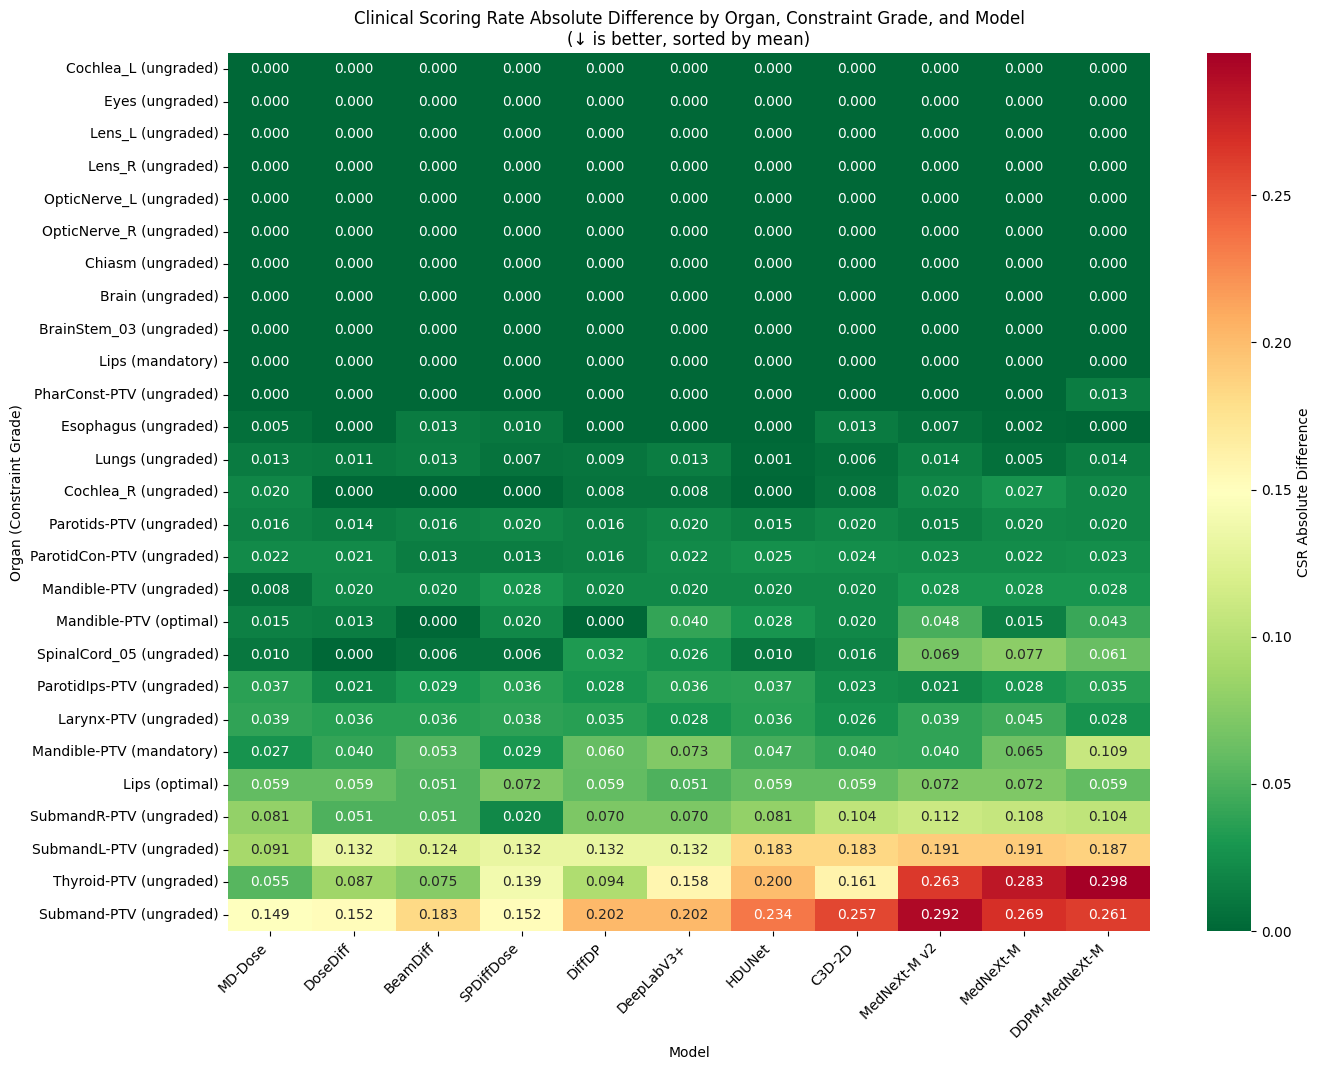

In [56]:
grades = ['mandatory', 'recommended', 'optimal', 'ungraded']

# Find available organ/grade combinations
first_result = pred_comparison.results_list[0]
available_rows = []
for organ in GDPHMM_OAR_V3:
    for grade in grades:
        metric_name = f'vol_compliance/{organ}/csr_abs_diff_{grade}'
        if metric_name in first_result.volume_metrics.columns:
            available_rows.append((organ, grade, metric_name))

# Build heatmap data
heatmap_data = []
for result, label in zip(pred_comparison.results_list, pred_comparison.result_labels):
    row = {'model': label}
    for organ, grade, metric_name in available_rows:
        row_label = f'{organ} ({grade})'
        row[row_label] = result.volume_metrics[metric_name].mean()
    heatmap_data.append(row)

df_heatmap = pd.DataFrame(heatmap_data).set_index('model')

# Sort rows (organs) and columns (models) by mean score
df_heatmap_sorted = df_heatmap.T
df_heatmap_sorted = df_heatmap_sorted.loc[df_heatmap_sorted.mean(axis=1).sort_values().index]
df_heatmap_sorted = df_heatmap_sorted[df_heatmap_sorted.mean(axis=0).sort_values().index]

# Create heatmap
fig, ax = plt.subplots(figsize=(14, max(10, len(available_rows) * 0.4)))
sns.heatmap(df_heatmap_sorted, annot=True, fmt='.3f', cmap='RdYlGn_r', ax=ax,
            cbar_kws={'label': 'CSR Absolute Difference'})
ax.set_xlabel('Model')
ax.set_ylabel('Organ (Constraint Grade)')
ax.set_title('Clinical Scoring Rate Absolute Difference by Organ, Constraint Grade, and Model\n(↓ is better, sorted by mean)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

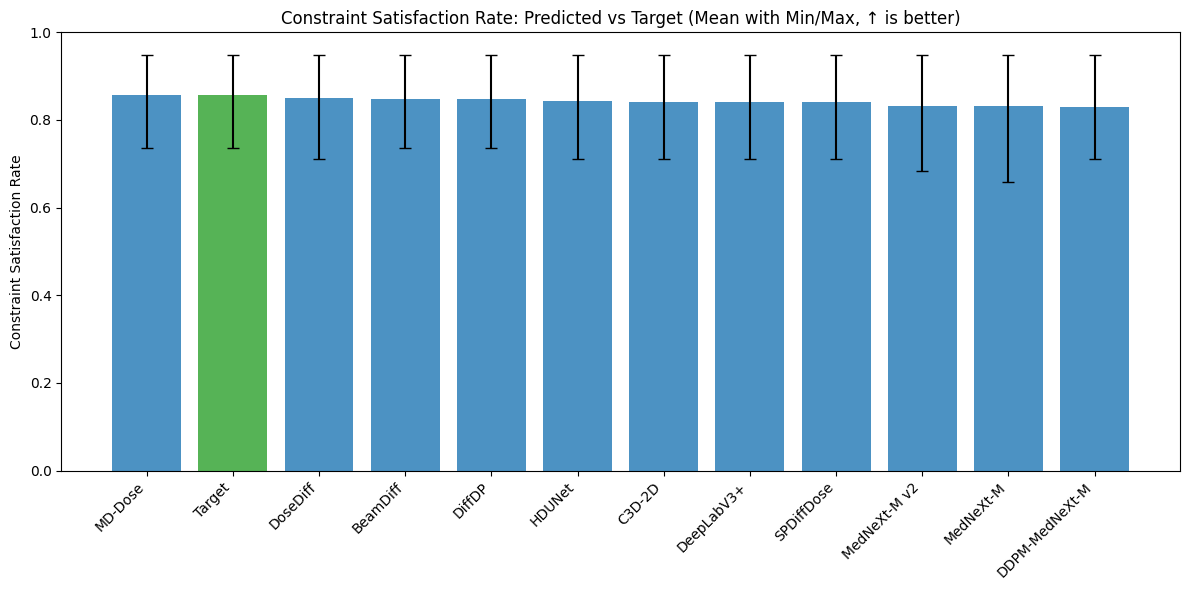

In [57]:
# Bar plot comparing CSR predicted vs target
fig, ax = plt.subplots(figsize=(12, 6))

# Collect data for each model
data = []
for result, label in zip(pred_comparison.results_list, pred_comparison.result_labels):
    values = result.volume_metrics['vol_csr_all/csr_pred']
    mean = values.mean()
    min_val = values.min()
    max_val = values.max()
    data.append((label, mean, min_val, max_val, 'tab:blue'))

# Add target (same for all models, use first one)
first_result = pred_comparison.results_list[0]
target_values = first_result.volume_metrics['vol_csr_all/csr_target']
target_mean = target_values.mean()
target_min = target_values.min()
target_max = target_values.max()
data.append(('Target', target_mean, target_min, target_max, 'tab:green'))

# Sort by mean (descending)
data.sort(key=lambda x: x[1], reverse=True)

models = [d[0] for d in data]
means = [d[1] for d in data]
err_lower = [d[1] - d[2] for d in data]  # mean - min
err_upper = [d[3] - d[1] for d in data]  # max - mean
colors = [d[4] for d in data]

# Create bar plot
x = range(len(models))
bars = ax.bar(x, means, yerr=[err_lower, err_upper], capsize=4, color=colors, alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel('Constraint Satisfaction Rate')
ax.set_title('Constraint Satisfaction Rate: Predicted vs Target (Mean with Min/Max, ↑ is better)')
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

/var/folders/zl/w6zt87md14j4524by47x78j00000gq/T/ipykernel_17289/2993291028.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)


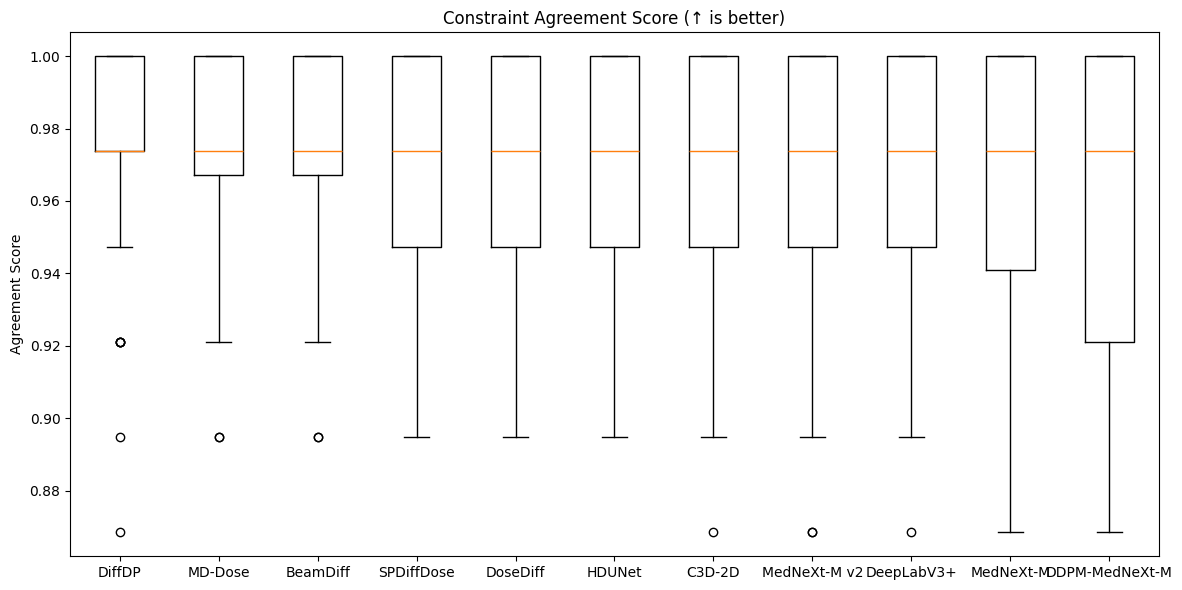

In [58]:
# Box plot comparing agreement score
fig, ax = plt.subplots(figsize=(12, 6))

# Collect data for each model
data = []
labels = []
for result, label in zip(pred_comparison.results_list, pred_comparison.result_labels):
    values = result.volume_metrics['vol_agreement/agreement_all']
    data.append(values)
    labels.append(label)

# Sort by median (desc), then IQR (asc), then range (asc)
def sort_key(i):
    v = data[i]
    median = v.median()
    iqr = v.quantile(0.75) - v.quantile(0.25)
    range_val = v.max() - v.min()
    return (-median, iqr, range_val)

sorted_indices = sorted(range(len(data)), key=sort_key)
data = [data[i] for i in sorted_indices]
labels = [labels[i] for i in sorted_indices]

# Create box plot
ax.boxplot(data, labels=labels)
ax.set_ylabel('Agreement Score')
ax.set_title('Constraint Agreement Score (↑ is better)')

plt.tight_layout()
plt.show()

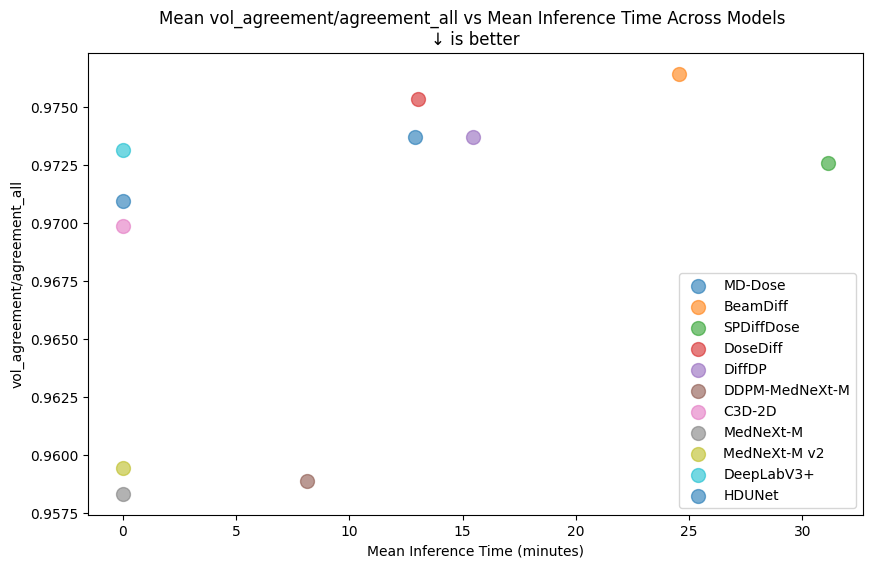

In [59]:
_ = pred_comparison.plot_quality_over_time('vol_agreement/agreement_all')

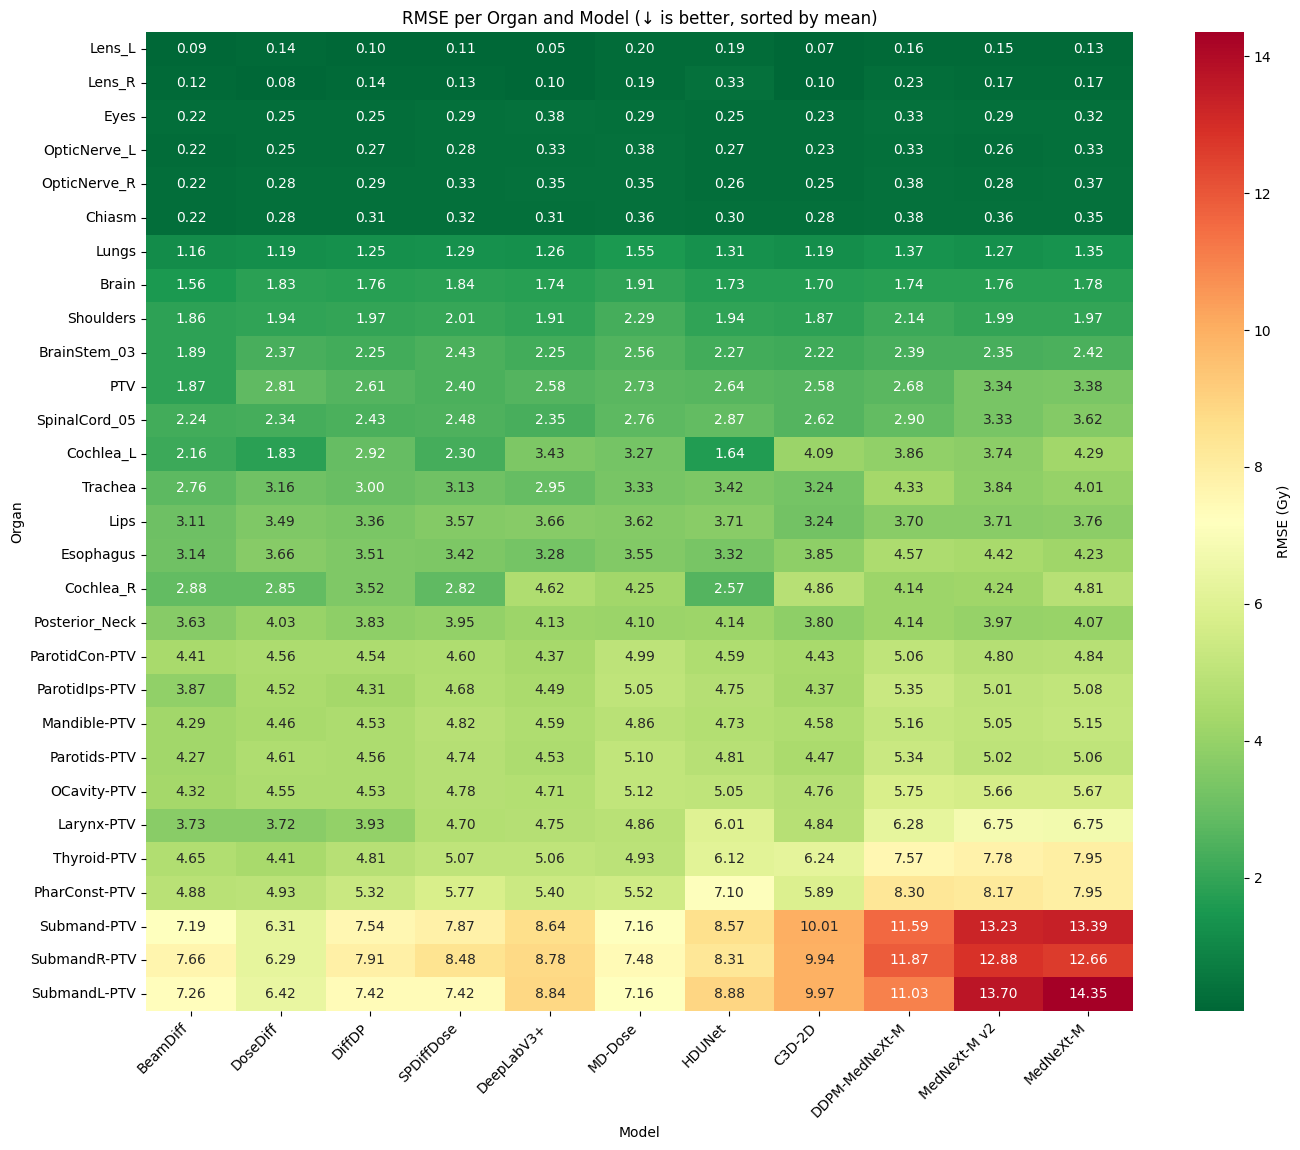

In [60]:
# Heatmap of vol_rmse per organ and model
organs = ['PTV'] + GDPHMM_OAR_V3

# Build heatmap data
heatmap_data = []
for result, label in zip(pred_comparison.results_list, pred_comparison.result_labels):
    row = {'model': label}
    for organ in organs:
        metric_name = f'vol_rmse/{organ}'
        if metric_name in result.volume_metrics.columns:
            row[organ] = result.volume_metrics[metric_name].mean()
    heatmap_data.append(row)

df_heatmap = pd.DataFrame(heatmap_data).set_index('model').T

# Sort rows (organs) by mean RMSE
df_heatmap = df_heatmap.loc[df_heatmap.mean(axis=1).sort_values().index]

# Sort columns (models) by mean RMSE
df_heatmap = df_heatmap[df_heatmap.mean(axis=0).sort_values().index]

# Create heatmap
fig, ax = plt.subplots(figsize=(14, max(8, len(df_heatmap) * 0.4)))
sns.heatmap(df_heatmap, annot=True, fmt='.2f', cmap='RdYlGn_r', ax=ax,
            cbar_kws={'label': 'RMSE (Gy)'})
ax.set_xlabel('Model')
ax.set_ylabel('Organ')
ax.set_title('RMSE per Organ and Model (↓ is better, sorted by mean)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

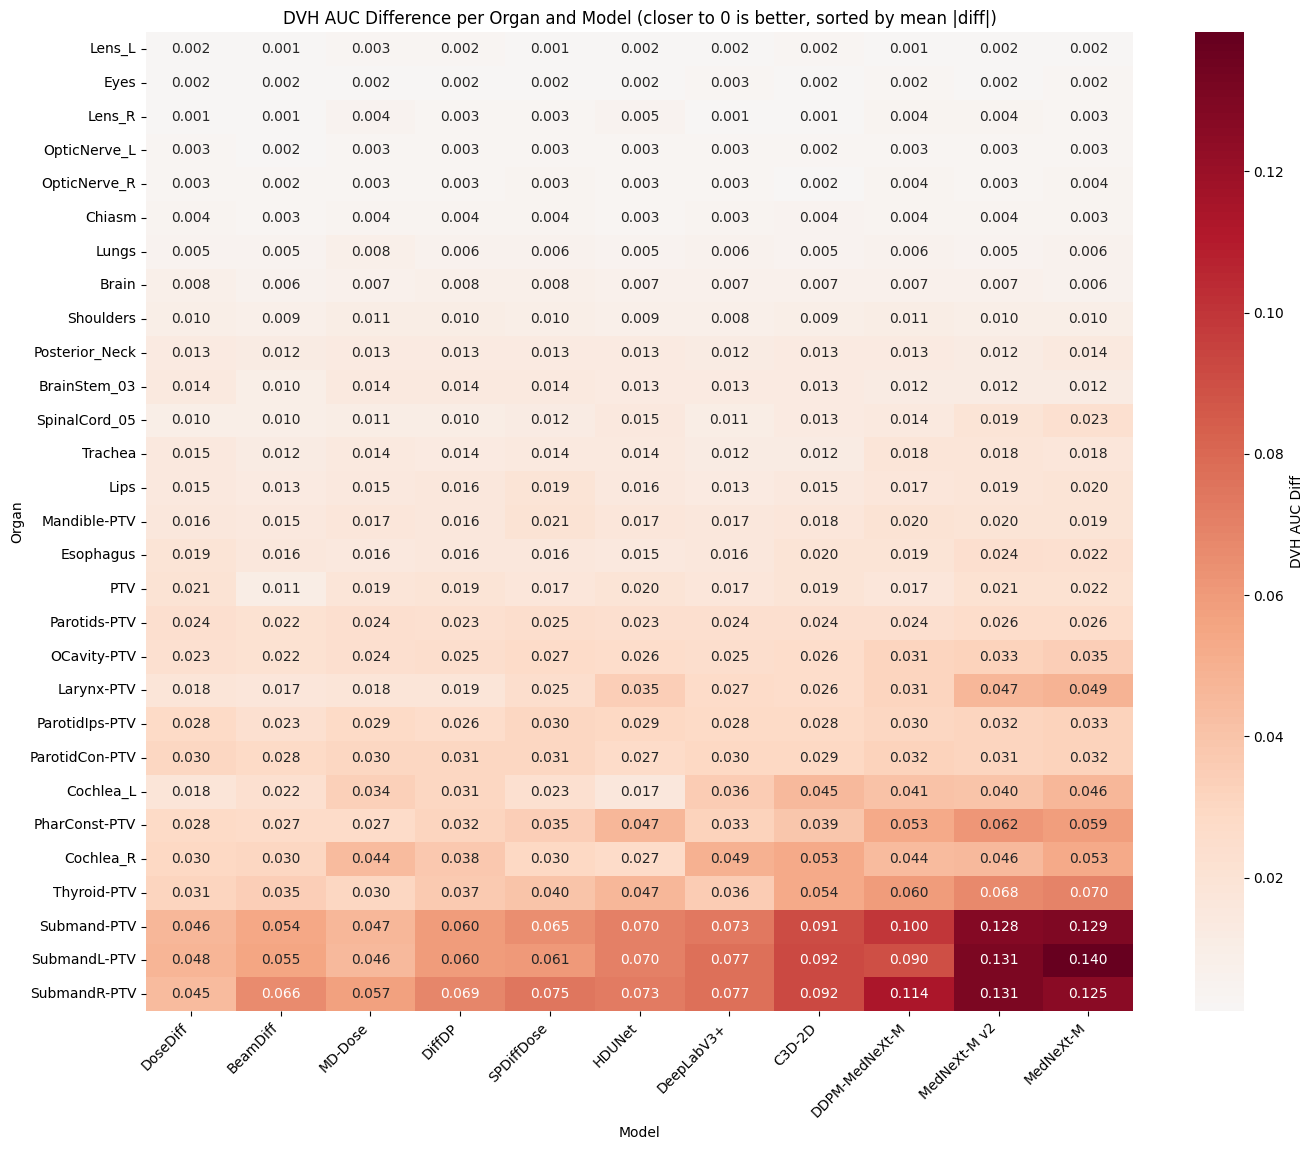

In [61]:
# Heatmap of vol_dvh_auc diff per organ and model
organs = ['PTV'] + GDPHMM_OAR_V3

# Build heatmap data
heatmap_data = []
for result, label in zip(pred_comparison.results_list, pred_comparison.result_labels):
    row = {'model': label}
    for organ in organs:
        metric_name = f'vol_dvh_auc/{organ}/diff'
        if metric_name in result.volume_metrics.columns:
            row[organ] = result.volume_metrics[metric_name].mean()
    heatmap_data.append(row)

df_heatmap = pd.DataFrame(heatmap_data).set_index('model').T

# Sort rows (organs) by mean absolute diff
df_heatmap = df_heatmap.loc[df_heatmap.abs().mean(axis=1).sort_values().index]

# Sort columns (models) by mean absolute diff
df_heatmap = df_heatmap[df_heatmap.abs().mean(axis=0).sort_values().index]

# Create heatmap
fig, ax = plt.subplots(figsize=(14, max(8, len(df_heatmap) * 0.4)))
sns.heatmap(df_heatmap, annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=ax,
            cbar_kws={'label': 'DVH AUC Diff'})
ax.set_xlabel('Model')
ax.set_ylabel('Organ')
ax.set_title('DVH AUC Difference per Organ and Model (closer to 0 is better, sorted by mean |diff|)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

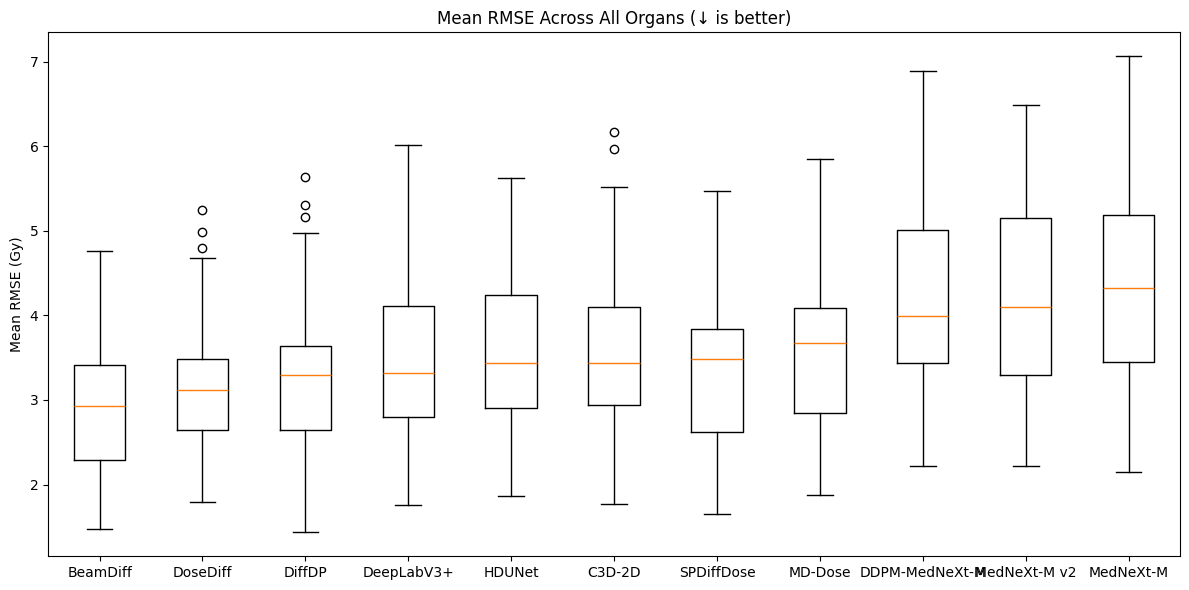

In [62]:
# Box plot of mean RMSE over all organs
fig, ax = plt.subplots(figsize=(12, 6))

organs = ['PTV'] + GDPHMM_OAR_V3

# Collect data for each model
data = []
labels = []
for result, label in zip(pred_comparison.results_list, pred_comparison.result_labels):
    # Calculate mean RMSE across all organs for each sample
    rmse_cols = [f'vol_rmse/{organ}' for organ in organs if f'vol_rmse/{organ}' in result.volume_metrics.columns]
    mean_rmse = result.volume_metrics[rmse_cols].mean(axis=1)
    data.append(mean_rmse)
    labels.append(label)

# Sort by median (ascending - lower is better)
sorted_indices = sorted(range(len(data)), key=lambda i: data[i].median())
data = [data[i] for i in sorted_indices]
labels = [labels[i] for i in sorted_indices]

# Create box plot
ax.boxplot(data, tick_labels=labels)
ax.set_ylabel('Mean RMSE (Gy)')
ax.set_title('Mean RMSE Across All Organs (↓ is better)')

plt.tight_layout()
plt.show()

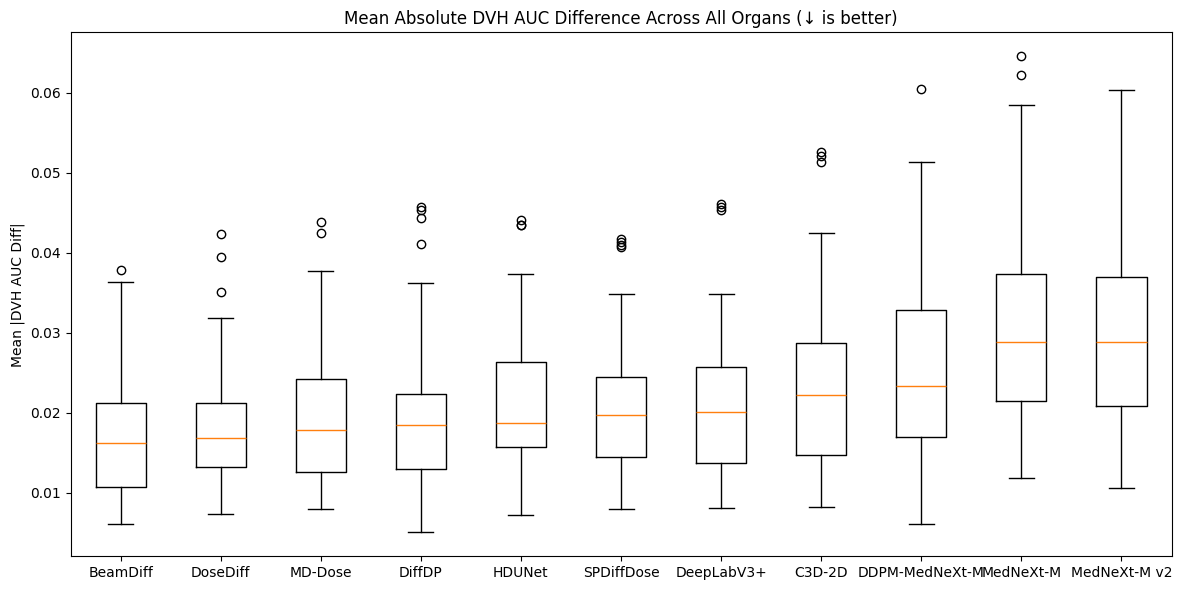

In [63]:
# Box plot of mean absolute DVH AUC diff over all organs
fig, ax = plt.subplots(figsize=(12, 6))

organs = ['PTV'] + GDPHMM_OAR_V3

# Collect data for each model
data = []
labels = []
for result, label in zip(pred_comparison.results_list, pred_comparison.result_labels):
    # Calculate mean absolute DVH AUC diff across all organs for each sample
    dvh_cols = [f'vol_dvh_auc/{organ}/diff' for organ in organs if f'vol_dvh_auc/{organ}/diff' in result.volume_metrics.columns]
    mean_dvh_diff = result.volume_metrics[dvh_cols].abs().mean(axis=1)
    data.append(mean_dvh_diff)
    labels.append(label)

# Sort by median (ascending - lower is better)
sorted_indices = sorted(range(len(data)), key=lambda i: data[i].median())
data = [data[i] for i in sorted_indices]
labels = [labels[i] for i in sorted_indices]

# Create box plot
ax.boxplot(data, tick_labels=labels)
ax.set_ylabel('Mean |DVH AUC Diff|')
ax.set_title('Mean Absolute DVH AUC Difference Across All Organs (↓ is better)')

plt.tight_layout()
plt.show()

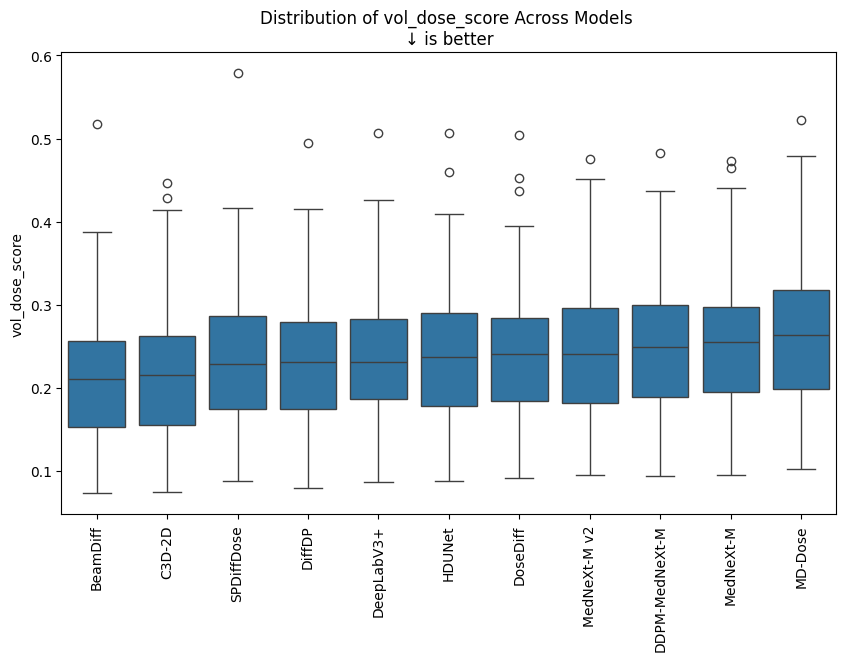

In [64]:
_ = pred_comparison.plot_metric_distribution('vol_dose_score', sort=True)

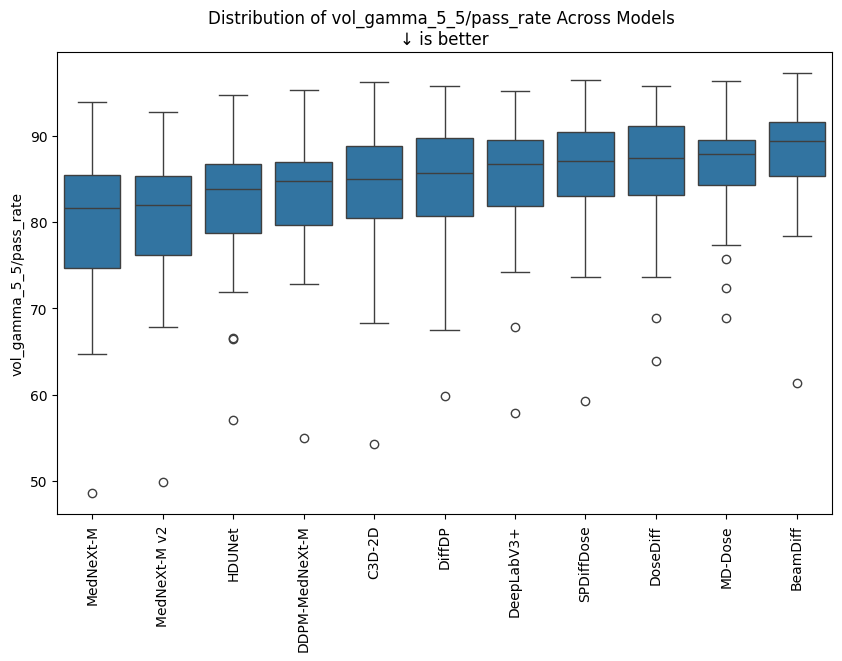

In [65]:
ax = pred_comparison.plot_metric_distribution('vol_gamma_5_5/pass_rate', sort=True)

In [ ]:
def analyze_metrics(comparison):
  # Get all numeric columns (excluding file_name, duration)
  exclude_cols = ['file_name', 'duration']
  metric_cols = [col for col in comparison.results_list[0].volume_metrics.columns
                  if col not in exclude_cols and
                  col.find('target') == -1 and
                  comparison.results_list[0].volume_metrics[col].dtype in ['float64', 'float32', 'int64', 'int32']]

  results = []

  for metric in metric_cols:
    metric_data = {}
    higher_better = is_higher_better(metric)

    for result, label in zip(comparison.results_list, comparison.result_labels):
      if metric in result.volume_metrics.columns:
        values = result.volume_metrics[metric].dropna()
        if len(values) > 0:
          metric_data[label] = {
            'median': values.median(),
            'variance': values.var(),
            'iqr': values.quantile(0.75) - values.quantile(0.25)
          }

    if len(metric_data) > 0:
      # Find model with best median (depends on direction)
      if higher_better:
        best_median_model = max(metric_data.keys(), key=lambda x: metric_data[x]['median'])
      else:
        best_median_model = min(metric_data.keys(), key=lambda x: metric_data[x]['median'])
      best_median_value = metric_data[best_median_model]['median']

      # Find model with lowest variance (always want low variance)
      best_var_model = min(metric_data.keys(), key=lambda x: metric_data[x]['variance'])
      best_var_value = metric_data[best_var_model]['variance']

      # Find model with lowest IQR (always want low spread)
      best_iqr_model = min(metric_data.keys(), key=lambda x: metric_data[x]['iqr'])
      best_iqr_value = metric_data[best_iqr_model]['iqr']

      results.append({
        'Metric': metric,
        'Direction': '↑' if higher_better else '↓',
        'Best Median Model': best_median_model,
        'Best Median Value': best_median_value,
        'Best Variance Model': best_var_model,
        'Best Variance Value': best_var_value,
        'Best IQR Model': best_iqr_model,
        'Best IQR Value': best_iqr_value
      })

  return pd.DataFrame(results)

pred_analysis = analyze_metrics(pred_comparison)
display(pred_analysis)

,Metric,Direction,Best Median Model,Best Median Value,Best Variance Model,Best Variance Value,Best IQR Model,Best IQR Value
0,vol_mse,↓,BeamDiff,0.938317,BeamDiff,2.615572e-01,BeamDiff,0.495688
1,vol_rmse,↓,BeamDiff,0.968662,BeamDiff,5.905562e-02,BeamDiff,0.261757
2,vol_dvh,↓,BeamDiff,0.270533,BeamDiff,1.915263e-01,MedNeXt-M v2,0.415224
3,vol_dvh_auc/pred,↓,MD-Dose,0.027153,MedNeXt-M v2,5.328231e-05,DiffDP,0.007611
4,vol_dvh_auc/diff,↓,BeamDiff,0.000491,BeamDiff,6.306866e-07,DDPM-MedNeXt-M,0.000761
...,...,...,...,...,...,...,...,...
294,vol_dvh_auc/Lens_L/diff,↓,DoseDiff,0.000000,SPDiffDose,2.796389e-06,DoseDiff,0.000505
295,vol_dvh_auc/SubmandR-PTV/pred,↓,MD-Dose,0.326596,DoseDiff,1.080074e-02,HDUNet,0.133250
296,vol_dvh_auc/SubmandR-PTV/diff,↓,MD-Dose,0.029576,DoseDiff,1.496804e-03,DoseDiff,0.054873
297,vol_dvh_auc/Lens_R/pred,↓,MD-Dose,0.006494,DiffDP,1.843710e-05,DeepLabV3+,0.003704


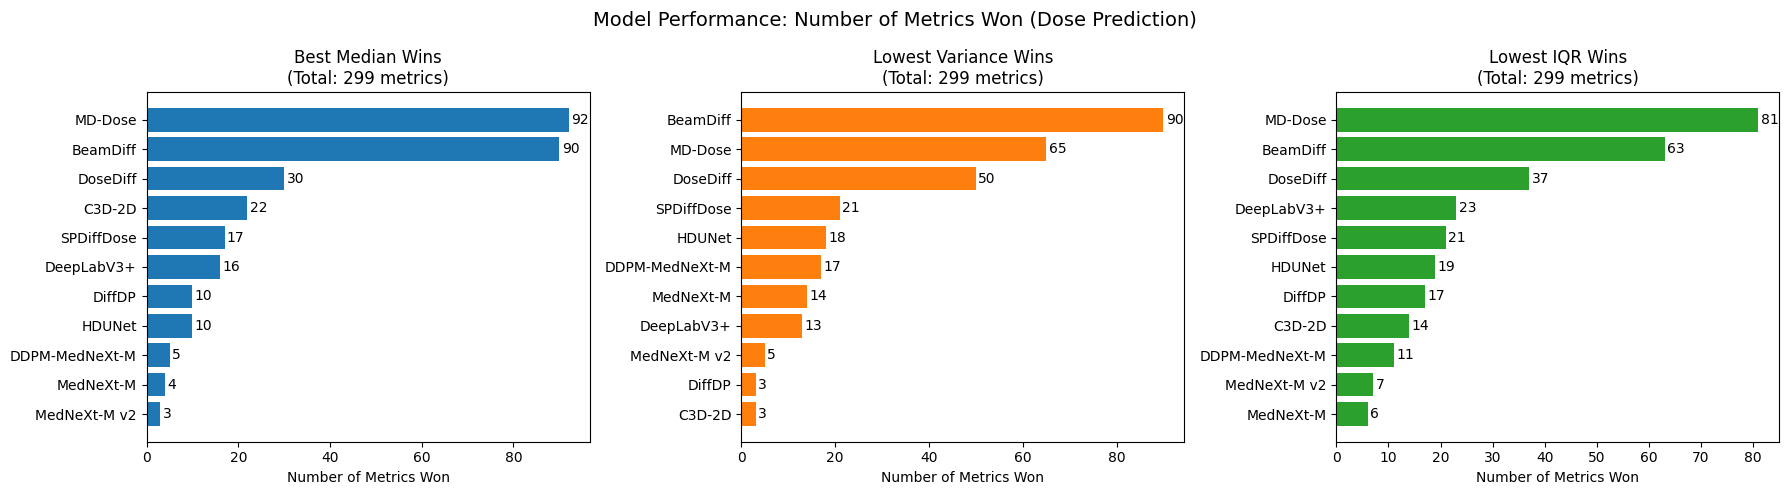

In [67]:
# Bar plots showing win frequency for each model
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Count wins for each category
median_wins = pred_analysis['Best Median Model'].value_counts().sort_values(ascending=True)
var_wins = pred_analysis['Best Variance Model'].value_counts().sort_values(ascending=True)
iqr_wins = pred_analysis['Best IQR Model'].value_counts().sort_values(ascending=True)

# Plot 1: Best Median wins
axes[0].barh(median_wins.index, median_wins.values, color='tab:blue')
axes[0].set_xlabel('Number of Metrics Won')
axes[0].set_title(f'Best Median Wins\n(Total: {len(pred_analysis)} metrics)')
for i, v in enumerate(median_wins.values):
  axes[0].text(v + 0.5, i, str(v), va='center')

# Plot 2: Best Variance wins
axes[1].barh(var_wins.index, var_wins.values, color='tab:orange')
axes[1].set_xlabel('Number of Metrics Won')
axes[1].set_title(f'Lowest Variance Wins\n(Total: {len(pred_analysis)} metrics)')
for i, v in enumerate(var_wins.values):
  axes[1].text(v + 0.5, i, str(v), va='center')

# Plot 3: Best IQR wins
axes[2].barh(iqr_wins.index, iqr_wins.values, color='tab:green')
axes[2].set_xlabel('Number of Metrics Won')
axes[2].set_title(f'Lowest IQR Wins\n(Total: {len(pred_analysis)} metrics)')
for i, v in enumerate(iqr_wins.values):
  axes[2].text(v + 0.5, i, str(v), va='center')

plt.suptitle('Model Performance: Number of Metrics Won (Dose Prediction)', fontsize=14)
plt.tight_layout()
plt.show()


In [72]:
models_to_compare = [
    # Diffusion - 10x pred
    (mamba_099_pred, mamba_199_pred),
    (beamdiff_099_pred, beamdiff_199_pred),
    (spdiffdose_099_pred, spdiffdose_199_pred),
    (dosediff_099_pred, dosediff_199_pred),
    (diffdp_099_pred, diffdp_199_pred),
    (ddpm_mednext_m_099_pred, ddpm_mednext_m_199_pred),
    # UNet - 10x pred
    (c3d_2d_099_pred, c3d_2d_199_pred),
    (mednext_m_099_pred, mednext_m_199_pred),
    (mednext_v2_m_099_pred, mednext_v2_m_199_pred),
    (deeplabv3plus_099_pred, deeplabv3plus_199_pred),
    (hdunet_099_pred, hdunet_199_pred),
]

model_labels = {
  '100-mamba': 'MD-Dose',
  '101-beamdiff': 'BeamDiff',
  '102-spdiffdose': 'SPDiffDose',
  '103-dosediff': 'DoseDiff',
  '104-diffdp': 'DiffDP',
  '108-ddpm-mednext-m': 'DDPM-MedNeXt-M',
  '105-c3d-2d': 'C3D-2D',
  '106-mednext-m': 'MedNeXt-M',
  '107-deeplabv3plus': 'DeepLabV3+',
  '109-hdunet': 'HDUNet',
  '110-mednext-v2-m': 'MedNeXt-M v2',
}

# Compare pairs on vol_agreement/agreement_all, avg vol_rmse, avg vol_dvh_auc diff
organs = ['PTV'] + GDPHMM_OAR_V3

comparison_data = []
for model_a, model_b in models_to_compare:
    model_name = model_labels[model_a.model_name]

    # vol_agreement/agreement_all
    agreement_a = model_a.volume_metrics['vol_agreement/agreement_all'].mean()
    agreement_b = model_b.volume_metrics['vol_agreement/agreement_all'].mean()

    # Average vol_rmse over all organs
    rmse_cols = [f'vol_rmse/{organ}' for organ in organs if f'vol_rmse/{organ}' in model_a.volume_metrics.columns]
    avg_rmse_a = model_a.volume_metrics[rmse_cols].mean().mean()
    avg_rmse_b = model_b.volume_metrics[rmse_cols].mean().mean()

    # Average vol_dvh_auc diff over all organs
    dvh_cols = [f'vol_dvh_auc/{organ}/diff' for organ in organs if f'vol_dvh_auc/{organ}/diff' in model_a.volume_metrics.columns]
    avg_dvh_a = model_a.volume_metrics[dvh_cols].abs().mean().mean()
    avg_dvh_b = model_b.volume_metrics[dvh_cols].abs().mean().mean()

    comparison_data.append({
        'Model': model_name,
        f'Agreement (ep{model_a.epoch})': agreement_a,
        f'Agreement (ep{model_b.epoch})': agreement_b,
        'Agreement Δ': agreement_b - agreement_a,
        f'Avg RMSE (ep{model_a.epoch})': avg_rmse_a,
        f'Avg RMSE (ep{model_b.epoch})': avg_rmse_b,
        'RMSE Δ': avg_rmse_b - avg_rmse_a,
        f'Avg |DVH Diff| (ep{model_a.epoch})': avg_dvh_a,
        f'Avg |DVH Diff| (ep{model_b.epoch})': avg_dvh_b,
        'DVH Δ': avg_dvh_b - avg_dvh_a,
    })

df_comparison = pd.DataFrame(comparison_data)
df_comparison

,Model,Agreement (ep99),Agreement (ep199),Agreement Δ,Avg RMSE (ep99),Avg RMSE (ep199),RMSE Δ,Avg |DVH Diff| (ep99),Avg |DVH Diff| (ep199),DVH Δ
0,MD-Dose,0.962171,0.973684,0.011513,4.388058,3.445636,-0.942422,0.031596,0.019842,-0.011754
1,BeamDiff,0.980811,0.976425,-0.004386,2.959778,2.961567,0.001790,0.017439,0.018340,0.000901
2,SPDiffDose,0.972588,0.972588,0.000000,3.260291,3.311430,0.051139,0.020319,0.021815,0.001496
3,DoseDiff,0.976425,0.975329,-0.001096,3.023070,3.018911,-0.004159,0.016930,0.018329,0.001399
4,DiffDP,0.975877,0.973684,-0.002193,3.268367,3.212743,-0.055624,0.021114,0.020985,-0.000129
5,DDPM-MedNeXt-M,0.961075,0.958882,-0.002193,4.346174,4.243763,-0.102411,0.028875,0.028359,-0.000515
6,C3D-2D,0.968202,0.969846,0.001645,3.573622,3.652461,0.078839,0.025024,0.026094,0.001071
7,MedNeXt-M,0.956689,0.958333,0.001645,4.611756,4.490218,-0.121539,0.034889,0.033977,-0.000912
8,MedNeXt-M v2,0.960526,0.959430,-0.001096,4.444457,4.397769,-0.046688,0.033041,0.033049,0.000008
9,DeepLabV3+,0.972588,0.973136,0.000548,3.480152,3.442335,-0.037817,0.022795,0.022857,0.000062


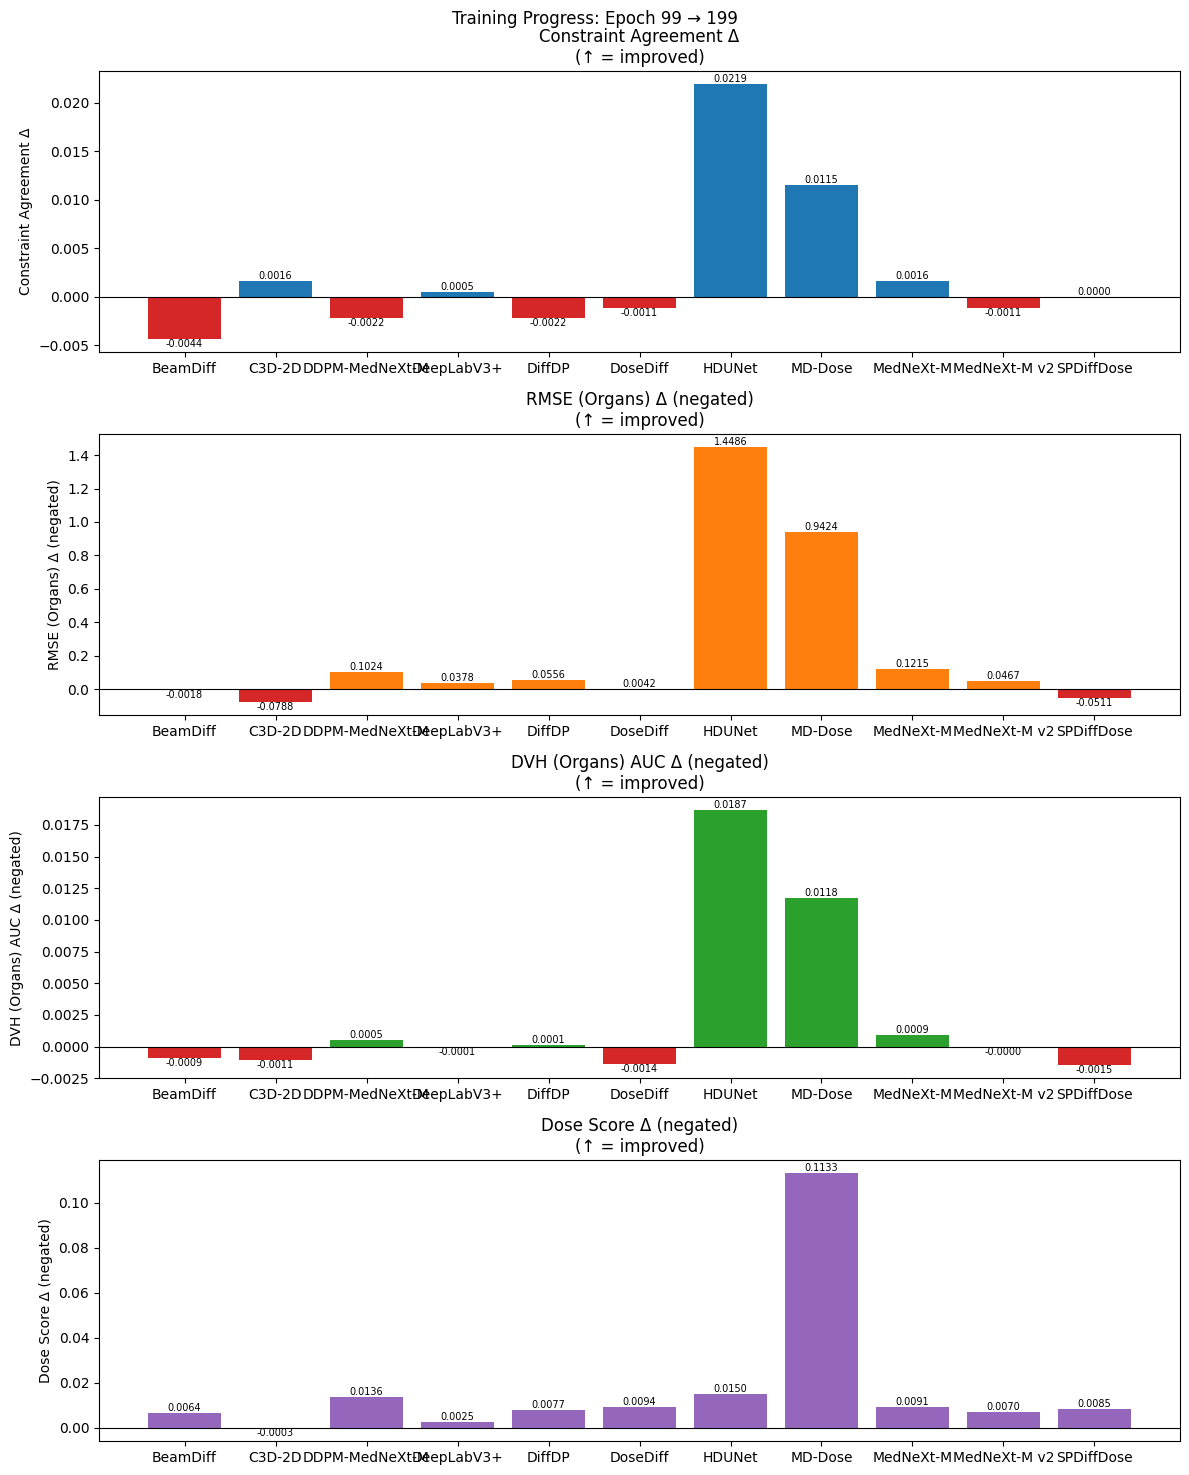

In [73]:
# Visualize training progress: are models still improving?
organs = ['PTV'] + GDPHMM_OAR_V3

# Compute deltas for each model pair
deltas = []
for model_a, model_b in models_to_compare:
    model_name = model_labels[model_a.model_name]

    dose_score_delta = -(model_b.volume_metrics['vol_dose_score'].mean() -
                        model_a.volume_metrics['vol_dose_score'].mean())

    # Agreement (higher is better, so positive delta = improvement)
    agreement_delta = (model_b.volume_metrics['vol_agreement/agreement_all'].mean() -
                       model_a.volume_metrics['vol_agreement/agreement_all'].mean())

    # RMSE (lower is better, so negative delta = improvement, we negate for visualization)
    rmse_cols = [f'vol_rmse/{organ}' for organ in organs if f'vol_rmse/{organ}' in model_a.volume_metrics.columns]
    rmse_delta = -(model_b.volume_metrics[rmse_cols].mean().mean() -
                   model_a.volume_metrics[rmse_cols].mean().mean())

    # DVH diff (lower is better, so negative delta = improvement, we negate for visualization)
    dvh_cols = [f'vol_dvh_auc/{organ}/diff' for organ in organs if f'vol_dvh_auc/{organ}/diff' in model_a.volume_metrics.columns]
    dvh_delta = -(model_b.volume_metrics[dvh_cols].abs().mean().mean() -
                  model_a.volume_metrics[dvh_cols].abs().mean().mean())

    deltas.append({
        'Model': model_name,
        'Dose Score': dose_score_delta,
        'Agreement': agreement_delta,
        'RMSE': rmse_delta,
        'DVH AUC': dvh_delta,
    })

df_deltas = pd.DataFrame(deltas)

# Sort by model name for consistent ordering
df_deltas = df_deltas.sort_values('Model').reset_index(drop=True)

# Create one plot per metric
fig, axes = plt.subplots(4, 1, figsize=(12, 15))

metrics = [
    ('Agreement', 'Constraint Agreement Δ', 'tab:blue'),
    ('RMSE', 'RMSE (Organs) Δ (negated)', 'tab:orange'),
    ('DVH AUC', 'DVH (Organs) AUC Δ (negated)', 'tab:green'),
    ('Dose Score', 'Dose Score Δ (negated)', 'tab:purple'),
]

for ax, (metric, label, color) in zip(axes, metrics):
    values = df_deltas[metric]
    colors = [color if v >= 0 else 'tab:red' for v in values]

    bars = ax.bar(df_deltas['Model'], values, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
    ax.set_xlabel('')
    ax.set_ylabel(label)
    ax.set_title(f'{label}\n(↑ = improved)')

    # Add value labels on bars
    for bar, val in zip(bars, values):
        va = 'bottom' if val >= 0 else 'top'
        ax.annotate(f'{val:.4f}', xy=(bar.get_x() + bar.get_width()/2, val),
                    ha='center', va=va, fontsize=7)

fig.suptitle(f'Training Progress: Epoch {models_to_compare[0][0].epoch} → {models_to_compare[0][1].epoch}', fontsize=12)
plt.tight_layout()
plt.show()

# Dose Planning

In [4]:
# 20x plan models (200-series) - Diffusion
mamba_099_plan = ModelResults('200-mamba', 'ddpm-1000', 99, 'test', dataset)
mamba_199_plan = ModelResults('200-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_099_plan = ModelResults('201-beamdiff', 'ddpm-1000', 99, 'test', dataset)
beamdiff_199_plan = ModelResults('201-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_099_plan = ModelResults('202-spdiffdose', 'ddpm-1000', 99, 'test', dataset)
spdiffdose_199_plan = ModelResults('202-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_099_plan = ModelResults('203-dosediff', 'ddpm-1000', 99, 'test', dataset)
dosediff_199_plan = ModelResults('203-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_099_plan = ModelResults('204-diffdp', 'ddpm-1000', 99, 'test', dataset)
diffdp_199_plan = ModelResults('204-diffdp', 'ddpm-1000', 199, 'test', dataset)
ddpm_mednext_m_099_plan = ModelResults('208-ddpm-mednext-m', 'ddpm-1000', 99, 'test', dataset)
ddpm_mednext_m_199_plan = ModelResults('208-ddpm-mednext-m', 'ddpm-1000', 199, 'test', dataset)

# 20x plan models (200-series) - UNet
c3d_2d_099_plan = ModelResults('205-c3d-2d', 'unet', 99, 'test', dataset)
c3d_2d_199_plan = ModelResults('205-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_099_plan = ModelResults('206-mednext-m', 'unet', 99, 'test', dataset)
mednext_m_199_plan = ModelResults('206-mednext-m', 'unet', 199, 'test', dataset)
mednext_v2_m_099_plan = ModelResults('210-mednext-v2-m', 'unet', 99, 'test', dataset)
mednext_v2_m_199_plan = ModelResults('210-mednext-v2-m', 'unet', 199, 'test', dataset)
deeplabv3plus_099_plan = ModelResults('207-deeplabv3plus', 'unet', 99, 'test', dataset)
deeplabv3plus_199_plan = ModelResults('207-deeplabv3plus', 'unet', 199, 'test', dataset)
hdunet_099_plan = ModelResults('209-hdunet', 'unet', 99, 'test', dataset)
hdunet_199_plan = ModelResults('209-hdunet', 'unet', 199, 'test', dataset)

In [5]:
plan_comparison = ModelComparison([
    mamba_199_plan,
    beamdiff_199_plan,
    spdiffdose_199_plan,
    dosediff_199_plan,
    diffdp_199_plan,
    ddpm_mednext_m_199_plan,
    c3d_2d_199_plan,
    mednext_m_199_plan,
    mednext_v2_m_199_plan,
    deeplabv3plus_199_plan,
    hdunet_199_plan,
], [
  'MD-Dose',
  'BeamDiff',
  'SPDiffDose',
  'DoseDiff',
  'DiffDP',
  'DDPM-MedNeXt-M',
  'C3D-2D',
  'MedNeXt-M',
  'MedNeXt-M v2',
  'DeepLabV3+',
  'HDUNet',
])

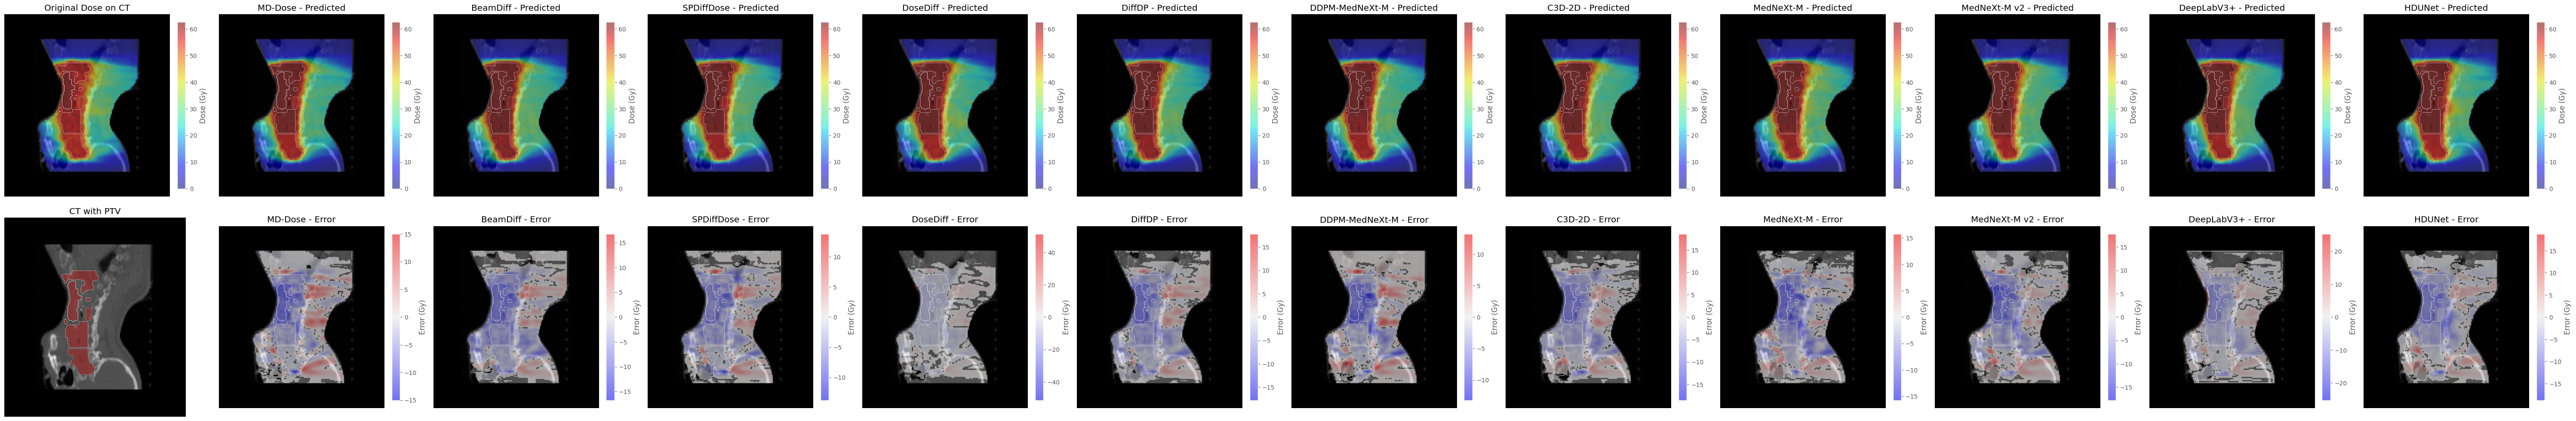

In [6]:
# sample = '0522c0027+A4Ac+MOS_30413'
# sample = 'HNSCC-01-0057+A4Ac+MOS_50995'
# sample = 'HNSCC-01-0060+A4Ac+MOS_19273'
# sample = '0522c0142+A4Ac+MOS_43691'
# sample = 'HNSCC-01-0164+A4Ac+MOS_52248' # 100
# sample = 'HN-CHUM-003+S2A4Ac+MOS_20285' ##
# sample = 'HNSCC-01-0026+A4Ac+MOS_5856'
# sample = '0522c0723+A4Ac+MOS_2890'
# sample = '0522c0629+A4Ac+MOS_1367'
# sample = 'HNC_004+A4Ac+MOS_11506' #
sample = 'HNSCC-01-0006+A4Ac+MOS_15521'

ax = plan_comparison.visualise_slice_comparison_with_ct(sample, 110, axis='sagittal')

1. Alignment of PTV (conformity index, homogeneity index)
2. Falloff outside PTV (gradient index, paddick gradient index)
3. Constraints + AUC (DVH metrics)
4. Anomalies + Voxel Comparison (RMSE, gamma index)

## Alignment of PTV

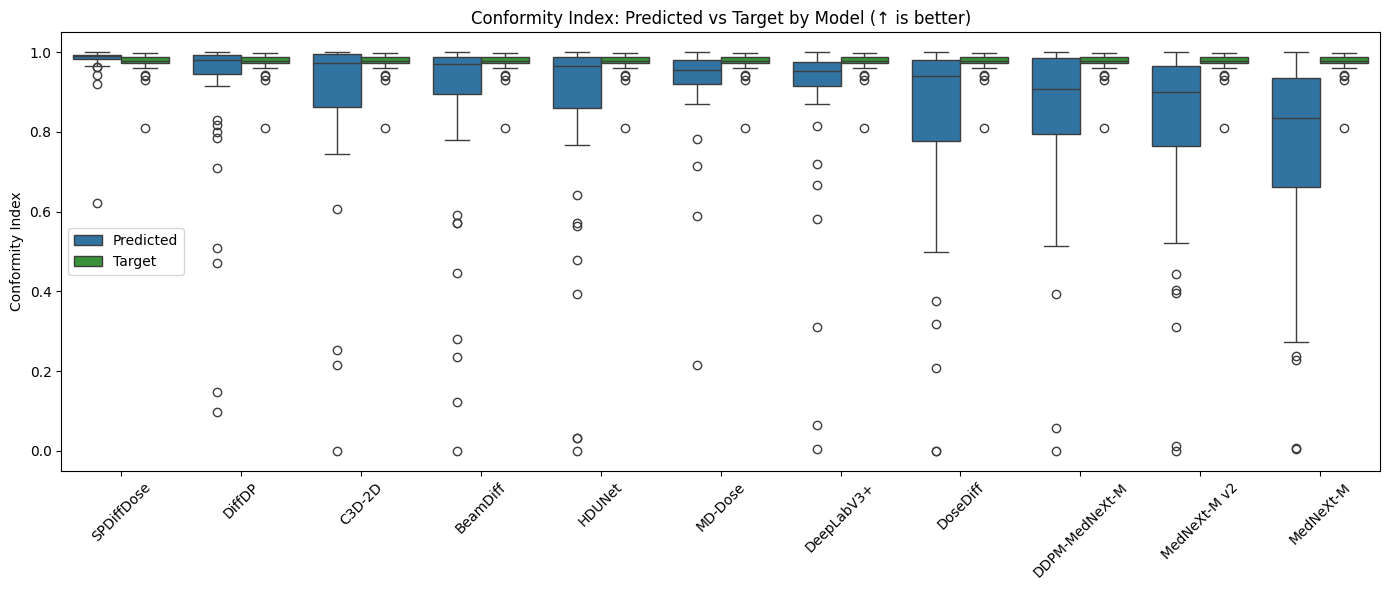

In [30]:
# Grouped boxplot: Conformity Index - Predicted vs Target for each model
fig, ax = plt.subplots(figsize=(14, 6))

data = []
for result, label in zip(plan_comparison.results_list, plan_comparison.result_labels):
    pred_values = result.volume_metrics['vol_conformity_index/high/pred']
    target_values = result.volume_metrics['vol_conformity_index/high/target']

    for val in pred_values:
        data.append({'Model': label, 'Type': 'Predicted', 'Conformity Index': val})
    for val in target_values:
        data.append({'Model': label, 'Type': 'Target', 'Conformity Index': val})

df = pd.DataFrame(data)

# Sort models by median predicted value
median_order = df[df['Type'] == 'Predicted'].groupby('Model')['Conformity Index'].median().sort_values(ascending=False).index.tolist()

sns.boxplot(x='Model', y='Conformity Index', hue='Type', data=df, ax=ax, order=median_order, palette={'Predicted': 'tab:blue', 'Target': 'tab:green'})
ax.tick_params(axis='x', rotation=45)
ax.set_title('Conformity Index: Predicted vs Target by Model (↑ is better)')
ax.set_xlabel('')
ax.legend(title='')
plt.tight_layout()
plt.show()

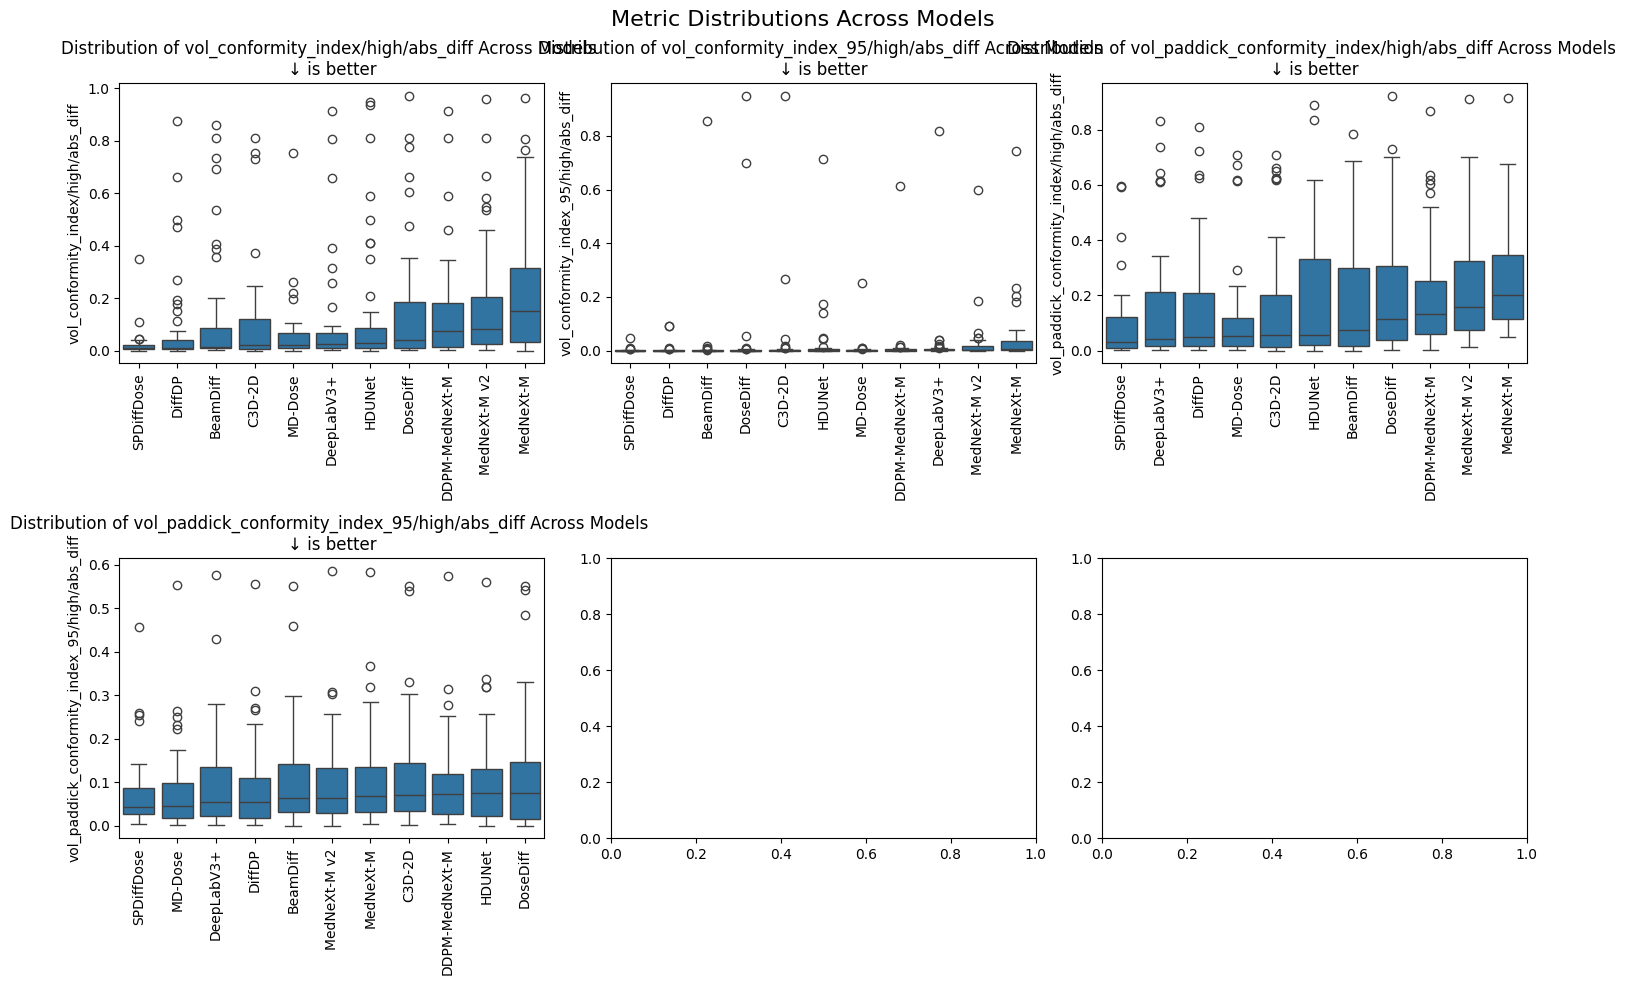

In [31]:
_ = plan_comparison.plot_metric_distributions([
  'vol_conformity_index/high/abs_diff',
  'vol_conformity_index_95/high/abs_diff',
  'vol_paddick_conformity_index/high/abs_diff',
  'vol_paddick_conformity_index_95/high/abs_diff'
], sort=True)

In [1]:
_ = plan_comparison.plot_metric_distribution('vol_homogeneity_index/high/abs_diff', sort=True)

NameError: name 'plan_comparison' is not defined

## Falloff outside PTV

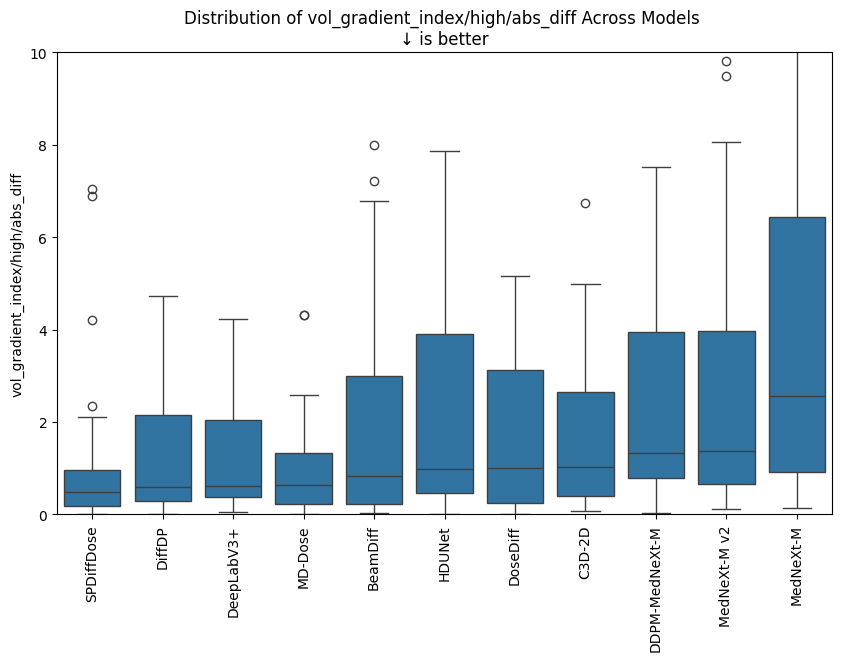

In [33]:
ax = plan_comparison.plot_metric_distribution('vol_gradient_index/high/abs_diff', sort=True)
_ = ax.set_ylim(0, 10)

## Constraints + AUC

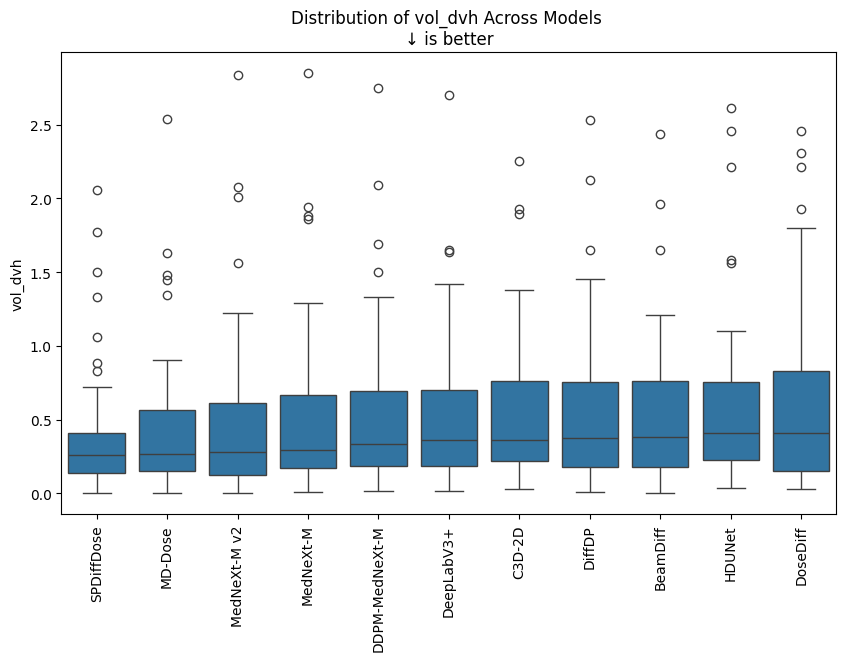

In [34]:
_ = plan_comparison.plot_metric_distribution('vol_dvh', sort=True)

## Anomalies + Voxel Comparison

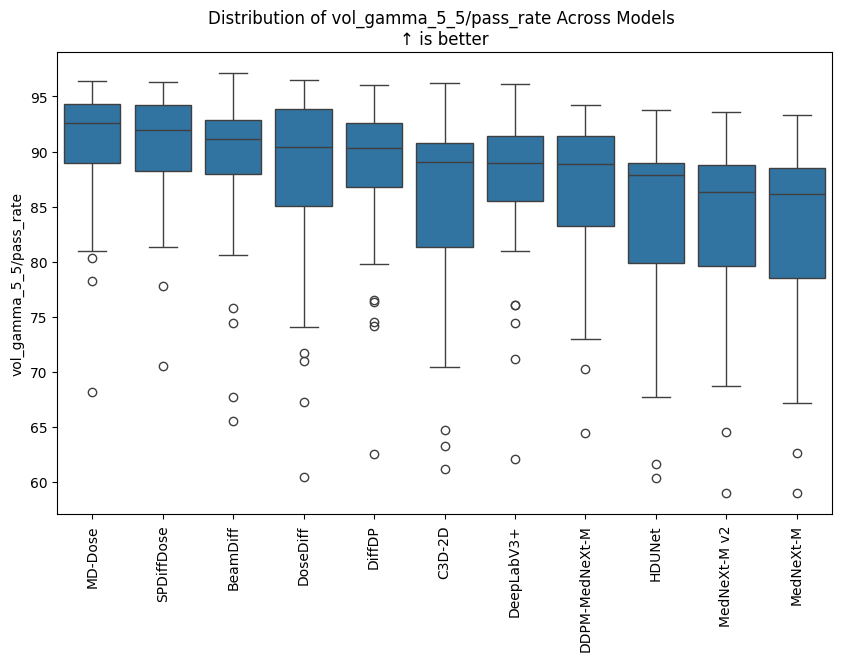

In [37]:
ax = plan_comparison.plot_metric_distribution('vol_gamma_5_5/pass_rate', sort=True)

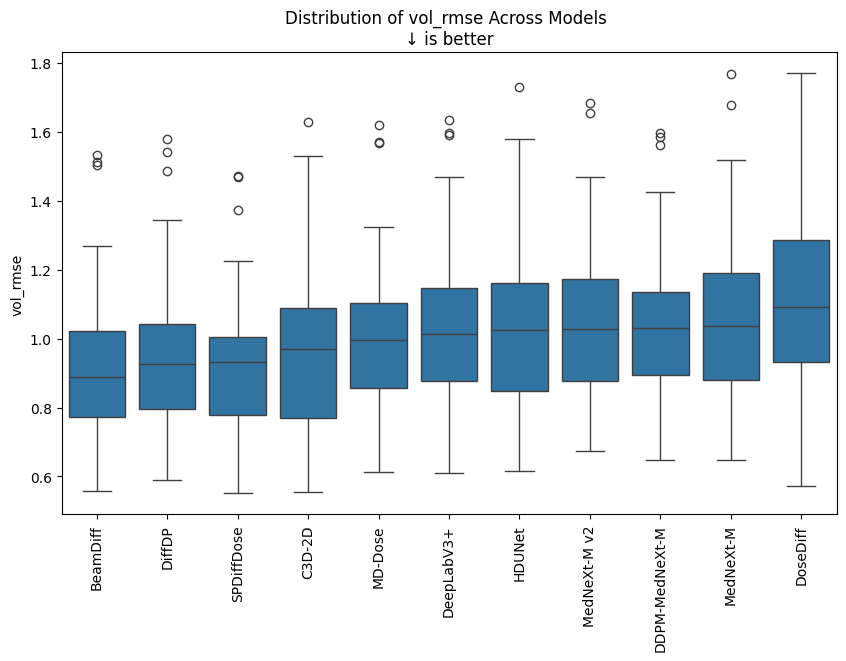

In [38]:
ax = plan_comparison.plot_metric_distribution('vol_rmse', sort=True)

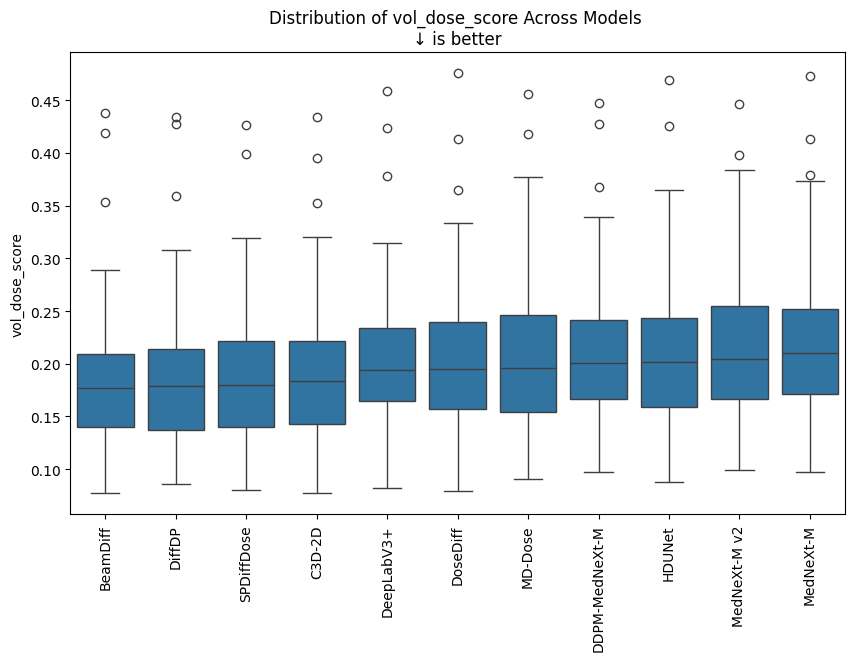

In [39]:
ax = plan_comparison.plot_metric_distribution('vol_dose_score', sort=True)

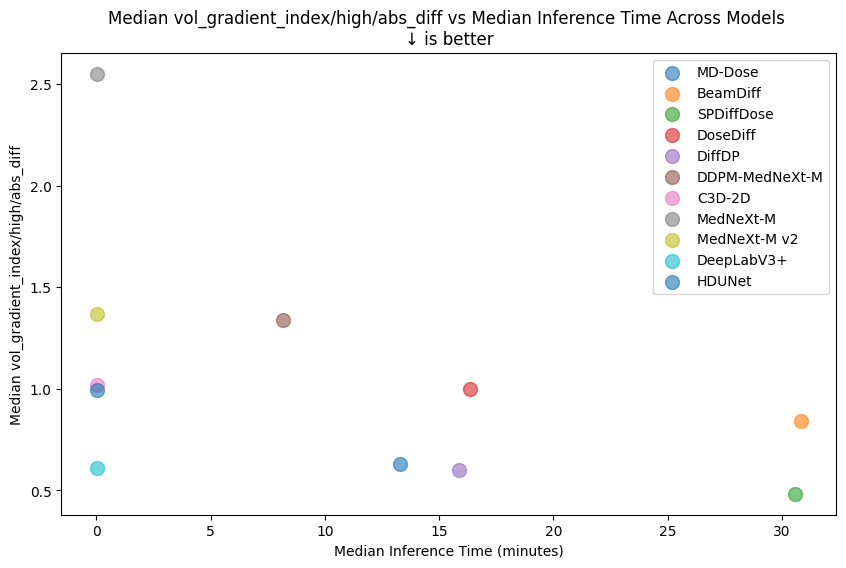

In [44]:
_ = plan_comparison.plot_quality_over_time('vol_gradient_index/high/abs_diff')

## Training Progress

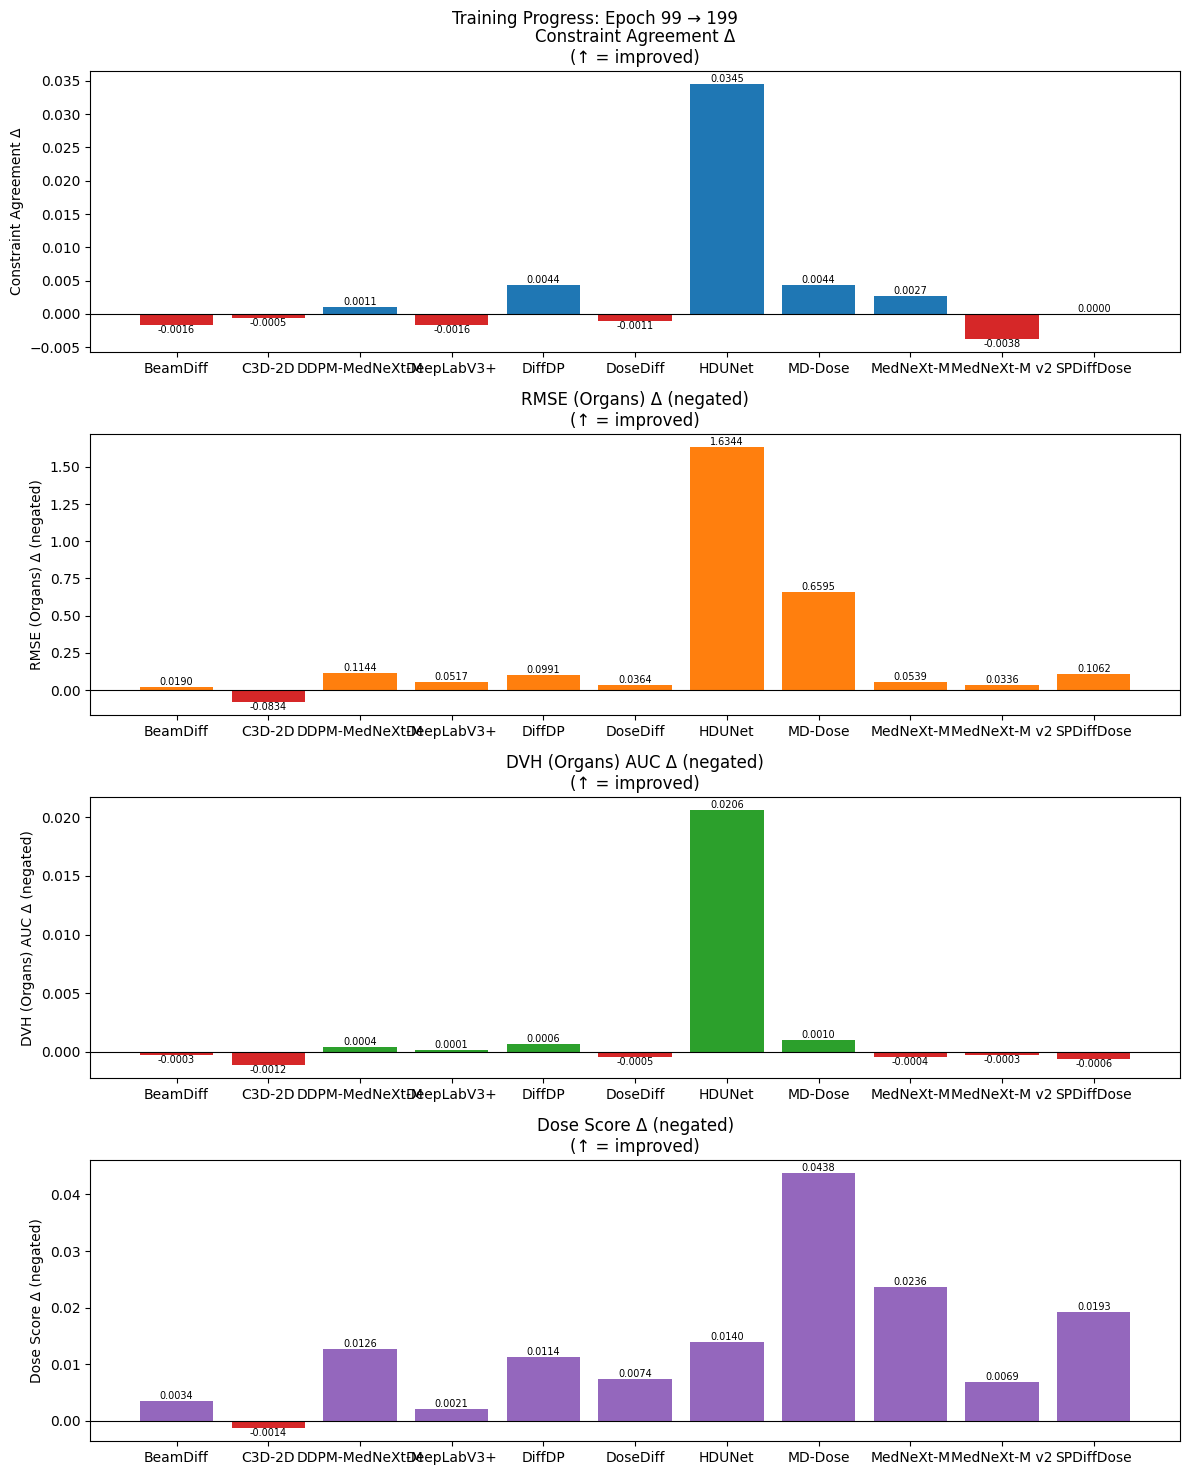

In [41]:
# Visualize training progress: are models still improving?
organs = ['PTV'] + GDPHMM_OAR_V3

models_to_compare = [
    # Diffusion - 20x plan
    (mamba_099_plan, mamba_199_plan),
    (beamdiff_099_plan, beamdiff_199_plan),
    (spdiffdose_099_plan, spdiffdose_199_plan),
    (dosediff_099_plan, dosediff_199_plan),
    (diffdp_099_plan, diffdp_199_plan),
    (ddpm_mednext_m_099_plan, ddpm_mednext_m_199_plan),
    # UNet - 20x plan
    (c3d_2d_099_plan, c3d_2d_199_plan),
    (mednext_m_099_plan, mednext_m_199_plan),
    (mednext_v2_m_099_plan, mednext_v2_m_199_plan),
    (deeplabv3plus_099_plan, deeplabv3plus_199_plan),
    (hdunet_099_plan, hdunet_199_plan),
]

model_labels = {
  '200-mamba': 'MD-Dose',
  '201-beamdiff': 'BeamDiff',
  '202-spdiffdose': 'SPDiffDose',
  '203-dosediff': 'DoseDiff',
  '204-diffdp': 'DiffDP',
  '208-ddpm-mednext-m': 'DDPM-MedNeXt-M',
  '205-c3d-2d': 'C3D-2D',
  '206-mednext-m': 'MedNeXt-M',
  '207-deeplabv3plus': 'DeepLabV3+',
  '209-hdunet': 'HDUNet',
  '210-mednext-v2-m': 'MedNeXt-M v2',
}


# Compute deltas for each model pair
deltas = []
for model_a, model_b in models_to_compare:
    model_name = model_labels[model_a.model_name]

    dose_score_delta = -(model_b.volume_metrics['vol_dose_score'].mean() -
                        model_a.volume_metrics['vol_dose_score'].mean())

    # Agreement (higher is better, so positive delta = improvement)
    agreement_delta = (model_b.volume_metrics['vol_agreement/agreement_all'].mean() -
                       model_a.volume_metrics['vol_agreement/agreement_all'].mean())

    # RMSE (lower is better, so negative delta = improvement, we negate for visualization)
    rmse_cols = [f'vol_rmse/{organ}' for organ in organs if f'vol_rmse/{organ}' in model_a.volume_metrics.columns]
    rmse_delta = -(model_b.volume_metrics[rmse_cols].mean().mean() -
                   model_a.volume_metrics[rmse_cols].mean().mean())

    # DVH diff (lower is better, so negative delta = improvement, we negate for visualization)
    dvh_cols = [f'vol_dvh_auc/{organ}/diff' for organ in organs if f'vol_dvh_auc/{organ}/diff' in model_a.volume_metrics.columns]
    dvh_delta = -(model_b.volume_metrics[dvh_cols].abs().mean().mean() -
                  model_a.volume_metrics[dvh_cols].abs().mean().mean())

    deltas.append({
        'Model': model_name,
        'Dose Score': dose_score_delta,
        'Agreement': agreement_delta,
        'RMSE': rmse_delta,
        'DVH AUC': dvh_delta,
    })

df_deltas = pd.DataFrame(deltas)

# Sort by model name for consistent ordering
df_deltas = df_deltas.sort_values('Model').reset_index(drop=True)

# Create one plot per metric
fig, axes = plt.subplots(4, 1, figsize=(12, 15))

metrics = [
    ('Agreement', 'Constraint Agreement Δ', 'tab:blue'),
    ('RMSE', 'RMSE (Organs) Δ (negated)', 'tab:orange'),
    ('DVH AUC', 'DVH (Organs) AUC Δ (negated)', 'tab:green'),
    ('Dose Score', 'Dose Score Δ (negated)', 'tab:purple'),
]

for ax, (metric, label, color) in zip(axes, metrics):
    values = df_deltas[metric]
    colors = [color if v >= 0 else 'tab:red' for v in values]

    bars = ax.bar(df_deltas['Model'], values, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
    ax.set_xlabel('')
    ax.set_ylabel(label)
    ax.set_title(f'{label}\n(↑ = improved)')

    # Add value labels on bars
    for bar, val in zip(bars, values):
        va = 'bottom' if val >= 0 else 'top'
        ax.annotate(f'{val:.4f}', xy=(bar.get_x() + bar.get_width()/2, val),
                    ha='center', va=va, fontsize=7)

fig.suptitle(f'Training Progress: Epoch {models_to_compare[0][0].epoch} → {models_to_compare[0][1].epoch}', fontsize=12)
plt.tight_layout()
plt.show()

## Metric Correlation

In [52]:
all_data = []
for result, label in zip(plan_comparison.results_list, plan_comparison.result_labels):
    df = result.volume_metrics.copy()
    df['model'] = label
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

correlation_matrix = combined_df.select_dtypes(include=['float64', 'float32', 'int64', 'int32']).corr(method='spearman')

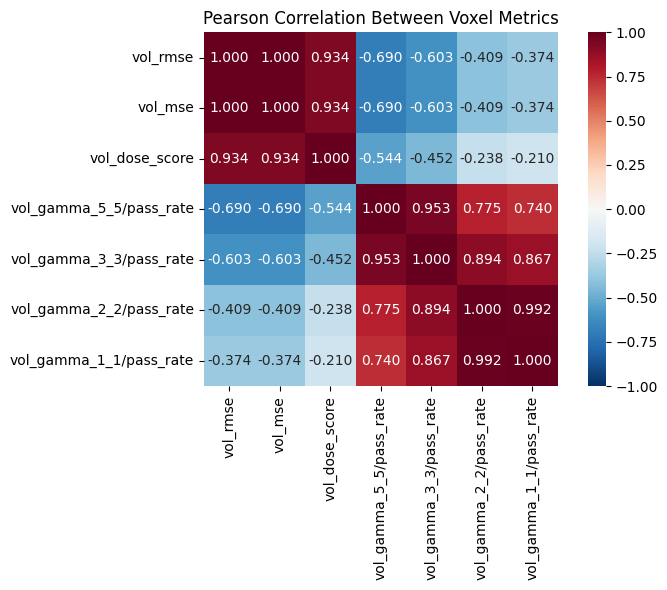

In [53]:
metrics = [
  'vol_rmse',
  'vol_mse',
  'vol_dose_score',
  'vol_gamma_5_5/pass_rate',
  'vol_gamma_3_3/pass_rate',
  'vol_gamma_2_2/pass_rate',
  'vol_gamma_1_1/pass_rate',
]

filtered_corr = correlation_matrix.loc[metrics][metrics]

# Visualize as heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(filtered_corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Pearson Correlation Between Voxel Metrics')
plt.tight_layout()
plt.show()

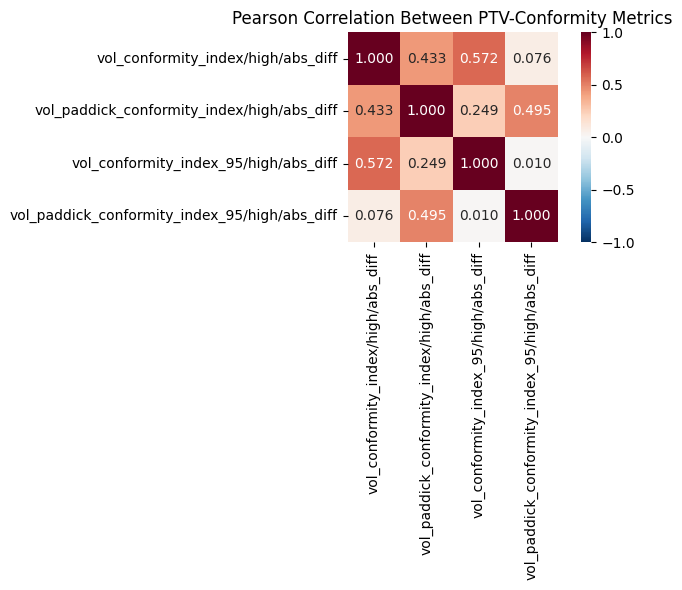

In [54]:
metrics = [
  'vol_conformity_index/high/abs_diff',
  'vol_paddick_conformity_index/high/abs_diff',
  'vol_conformity_index_95/high/abs_diff',
  'vol_paddick_conformity_index_95/high/abs_diff'
]

filtered_corr = correlation_matrix.loc[metrics][metrics]

# Visualize as heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(filtered_corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Pearson Correlation Between PTV-Conformity Metrics')
plt.tight_layout()
plt.show()

# Comparison Dose Prediction vs Dose Planning

In [ ]:
# look for metrics which have not improved